In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pd.set_option(
    "display.max_columns",
    100
)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.3f}"
)

In [3]:
DATA_DIR = Path(
    "../data/processed"
)

risk_path = (
    DATA_DIR
    / "price_risk_oof_predictions.csv"
)

risk = pd.read_csv(
    risk_path,
    parse_dates=[
        "week_end_date",
        "target_week",
    ]
)

risk = (
    risk
    .sort_values("target_week")
    .reset_index(drop=True)
)

print(
    "Rows:",
    len(risk)
)

print(
    "Period:",
    risk["target_week"].min(),
    "~",
    risk["target_week"].max()
)

risk.head()

Rows: 52
Period: 2025-10-05 00:00:00 ~ 2026-10-11 00:00:00


,fold,week_end_date,target_week,actual_price_index,predicted_price_index,current_price_index,qty_index_12w,actual_risk_level,predicted_risk_level,actual_risk_event,strict_alert,early_warning_alert,current_risk_event,next_risk_event,risk_transition,forecast_warning,current_risk_level,forecast_risk_level,operational_signal,alert_priority,qty_context,alert_priority_label
0,1,2025-09-28,2025-10-05,1.017,0.997,0.921,0.945,Normal,Normal,0,0,0,0,0,Normal,0,Normal,Normal,Stable,0,Normal Activity,Monitor
1,1,2025-10-05,2025-10-12,1.068,1.008,1.017,2.192,Watch,Normal,0,0,0,0,0,Normal,0,Normal,Normal,Stable,0,High Activity,Monitor
2,1,2025-10-19,2025-10-26,1.095,1.097,1.101,2.243,Watch,Watch,0,0,1,0,0,Normal,1,Watch,Watch,Watch Persistence,1,High Activity,Low
3,1,2025-10-26,2025-11-02,0.957,1.102,1.095,0.747,Normal,Watch,0,0,1,0,0,Normal,1,Watch,Watch,Watch Persistence,1,Normal Activity,Low
4,1,2025-11-02,2025-11-09,1.156,1.057,0.957,1.301,Risk,Watch,1,0,1,0,1,Onset,1,Normal,Watch,Early Watch,2,High Activity,Early Warning


In [4]:
required_cols = [
    "week_end_date",
    "target_week",
    "current_price_index",
    "predicted_price_index",
    "actual_price_index",
    "current_risk_level",
    "forecast_risk_level",
    "operational_signal",
    "alert_priority",
    "qty_index_12w",
]

missing_cols = [
    col
    for col in required_cols
    if col not in risk.columns
]

print(
    "Missing columns:",
    missing_cols
)

Missing columns: []


## Simulated Enterprise SCM Data Contract

본 노트북에서는 단일 Retail/DC가
양파 SKU를 주 단위로 관리한다고 가정한다.

기업 내부 데이터는 실제 데이터가 아닌
의사결정 로직 검증을 위한 Simulation 데이터이다.

| Field | Meaning | Source |
|---|---|---|
| avg_daily_demand_kg | 최근 기준 일평균 수요 | Simulated |
| demand_std_kg | 일 수요 변동성 | Simulated |
| on_hand_qty_kg | 의사결정 시점 가용재고 | Simulated |
| inbound_qty_kg | 입고 예정량 | Simulated |
| lead_time_days | 발주 후 입고까지 소요일 | Simulated |
| safety_stock_days | 안전재고 목표 일수 | Policy |
| review_period_days | 정기 발주주기 | Policy |
| moq_kg | 최소발주량 | Policy |
| predicted_price_index | 다음 주 가격 Risk Forecast | Validated Public-data Model |
| qty_index_12w | 온라인도매시장 거래활동 Context | Public Data |

Simulation 값은 실제 기업의 재고수준이나 발주정책을 의미하지 않는다.

In [5]:
SIMULATION_SEED = 42

BASE_DAILY_DEMAND_KG = 800

SAFETY_STOCK_DAYS = 3
REVIEW_PERIOD_DAYS = 7

MOQ_KG = 500

In [6]:
rng = np.random.default_rng(
    SIMULATION_SEED
)

sim = risk.copy()

sim["week_of_year"] = (
    sim["target_week"]
    .dt
    .isocalendar()
    .week
    .astype(int)
)

In [7]:
sim["demand_season_factor"] = (
    1
    +
    0.12
    *
    np.sin(
        2
        * np.pi
        * sim["week_of_year"]
        / 52
    )
)

In [8]:
sim["demand_noise"] = (
    rng.normal(
        loc=1.0,
        scale=0.08,
        size=len(sim)
    )
)

In [9]:
sim["avg_daily_demand_kg"] = (
    BASE_DAILY_DEMAND_KG
    *
    sim["demand_season_factor"]
    *
    sim["demand_noise"]
)

In [10]:
sim["avg_daily_demand_kg"] = (
    sim["avg_daily_demand_kg"]
    .clip(
        lower=500
    )
)

In [11]:
sim["weekly_demand_kg"] = (
    sim["avg_daily_demand_kg"]
    * 7
)

In [12]:
lead_time_choices = [
    7,
    7,
    7,
    7,
    10,
    14,
]

sim["lead_time_days"] = (
    rng.choice(
        lead_time_choices,
        size=len(sim),
        replace=True
    )
)

In [13]:
sim[
    "lead_time_days"
].value_counts().sort_index()

lead_time_days
7     39
10     7
14     6
Name: count, dtype: int64

In [14]:
def get_risk_buffer_days(row):

    current = row["current_risk_level"]
    forecast = row["forecast_risk_level"]

    # 새로운 Risk 진입 가능성
    if current == "Normal":

        if forecast == "Watch":
            return 2

        elif forecast == "Risk":
            return 4


    # Watch 상태에서 Risk 악화 예상
    elif current == "Watch":

        if forecast == "Risk":
            return 3

        elif forecast == "Watch":
            return 1


    # 이미 Risk인 경우
    # 높은 가격에서 선행매입을 추가 확대하지 않음
    elif current == "Risk":

        return 0


    return 0

In [15]:
sim["risk_buffer_days"] = (
    sim.apply(
        get_risk_buffer_days,
        axis=1
    )
)

In [16]:
sim[
    [
        "current_risk_level",
        "forecast_risk_level",
        "risk_buffer_days",
    ]
].value_counts()

current_risk_level  forecast_risk_level  risk_buffer_days
Normal              Normal               0                   29
Risk                Risk                 0                    6
Watch               Watch                1                    6
Risk                Watch                0                    4
Watch               Normal               0                    4
Normal              Watch                2                    3
Name: count, dtype: int64

In [17]:
sim_check = sim[
    [
        "target_week",

        "avg_daily_demand_kg",
        "weekly_demand_kg",

        "lead_time_days",

        "current_price_index",
        "predicted_price_index",

        "current_risk_level",
        "forecast_risk_level",

        "risk_buffer_days",
    ]
].copy()

sim_check.head(20)

,target_week,avg_daily_demand_kg,weekly_demand_kg,lead_time_days,current_price_index,predicted_price_index,current_risk_level,forecast_risk_level,risk_buffer_days
0,2025-10-05,721.879,"5,053.151",7,0.921,0.997,Normal,Normal,0
1,2025-10-12,647.986,"4,535.899",10,1.017,1.008,Normal,Normal,0
2,2025-10-26,757.922,"5,305.453",7,1.101,1.097,Watch,Watch,1
3,2025-11-02,775.245,"5,426.714",10,1.095,1.102,Watch,Watch,1
4,2025-11-09,614.492,"4,301.447",7,0.957,1.057,Normal,Watch,2
5,2025-11-16,659.632,"4,617.427",7,1.156,1.105,Risk,Watch,0
6,2025-11-23,753.090,"5,271.629",7,0.953,1.070,Normal,Watch,2
7,2025-11-30,736.276,"5,153.930",7,1.092,1.080,Watch,Watch,1
8,2025-12-07,764.928,"5,354.499",7,0.929,1.039,Normal,Normal,0
9,2025-12-14,723.999,"5,067.991",7,1.096,1.073,Watch,Watch,1


In [18]:
sim[
    [
        "avg_daily_demand_kg",
        "weekly_demand_kg",
        "lead_time_days",
        "risk_buffer_days",
    ]
].describe()

,avg_daily_demand_kg,weekly_demand_kg,lead_time_days,risk_buffer_days
count,52.000,52.000,52.000,52.000
mean,803.302,"5,623.117",8.212,0.231
std,85.872,601.106,2.346,0.546
min,614.492,"4,301.447",7.000,0.000
25%,736.066,"5,152.461",7.000,0.000
50%,795.058,"5,565.403",7.000,0.000
75%,869.910,"6,089.370",7.750,0.000
max,"1,011.632","7,081.425",14.000,2.000


In [19]:
sim['risk_buffer_days'].value_counts()

risk_buffer_days
0    43
1     6
2     3
Name: count, dtype: int64

## Demand Forecast Assumption

Simulation에서 실제 수요와 발주 시점의 예상수요를 분리한다.

- Actual Demand:
  계절성 + 주별 Random Variation을 포함한 실제 발생 수요
- Forecast Demand:
  계절성만 반영한 기대수요

이를 통해 발주정책이 미래 수요를 완벽히 알고 있다는
비현실적인 가정을 방지한다.

In [20]:
sim["forecast_daily_demand_kg"] = (
    BASE_DAILY_DEMAND_KG
    * sim["demand_season_factor"]
)

sim["forecast_weekly_demand_kg"] = (
    sim["forecast_daily_demand_kg"]
    * 7
)

sim["actual_weekly_demand_kg"] = (
    sim["weekly_demand_kg"]
)

In [21]:
sim["demand_forecast_error_pct"] = (
    (
        sim["actual_weekly_demand_kg"]
        - sim["forecast_weekly_demand_kg"]
    )
    / sim["forecast_weekly_demand_kg"]
    * 100
)

sim[
    [
        "forecast_weekly_demand_kg",
        "actual_weekly_demand_kg",
        "demand_forecast_error_pct",
    ]
].describe()

,forecast_weekly_demand_kg,actual_weekly_demand_kg,demand_forecast_error_pct
count,52.000,52.000,52.000
mean,"5,575.264","5,623.117",0.843
std,481.649,601.106,6.058
min,"4,928.000","4,301.447",-15.608
25%,"5,097.001","5,152.461",-3.295
50%,"5,559.500","5,565.403",1.769
75%,"6,045.618","6,089.370",5.089
max,"6,272.000","7,081.425",17.133


In [22]:
sim["lead_time_weeks"] = (
    np.ceil(
        sim["lead_time_days"] / 7
    )
    .astype(int)
)

In [23]:
sim[
    [
        "lead_time_days",
        "lead_time_weeks",
    ]
].value_counts().sort_index()

lead_time_days  lead_time_weeks
7               1                  39
10              2                   7
14              2                   6
Name: count, dtype: int64

In [24]:
def round_up_to_moq(
    qty,
    moq=MOQ_KG
):

    if qty <= 0:
        return 0.0

    return (
        np.ceil(qty / moq)
        * moq
    )

In [25]:
for qty in [
    0,
    100,
    499,
    500,
    501,
    1250,
]:

    print(
        qty,
        "→",
        round_up_to_moq(qty)
    )

0 → 0.0
100 → 500.0
499 → 500.0
500 → 500.0
501 → 1000.0
1250 → 1500.0


## Replenishment Policies

### Baseline Policy

외부 가격 Risk를 사용하지 않고
일반적인 Periodic Review 방식으로 재고를 보충한다.

Target Days =
Lead Time + Review Period + Safety Stock

### Risk-aware Policy

Baseline과 동일한 재고정책을 사용하되,
다음 주 가격 Risk Forecast가 Watch 신호를 줄 경우
제한적인 선행 Buffer를 추가한다.

Target Days =
Lead Time + Review Period + Safety Stock + Risk Buffer

두 정책은 동일한 Actual Demand,
Demand Forecast, Lead Time, MOQ 조건에서 비교한다.

In [26]:
def simulate_inventory_policy(
    sim_df,
    policy_name,
    use_risk_buffer=False,
    safety_stock_days=3,
):

    df = (
        sim_df
        .copy()
        .sort_values("target_week")
        .reset_index(drop=True)
    )

    # ---------------------------------------------
    # Initial Inventory
    # ---------------------------------------------

    initial_daily_demand = (
        df.loc[
            0,
            "forecast_daily_demand_kg"
        ]
    )

    initial_lead_days = (
        df.loc[
            0,
            "lead_time_days"
        ]
    )

    initial_target_days = (
        initial_lead_days
        + REVIEW_PERIOD_DAYS
        + safety_stock_days
    )

    on_hand = (
        initial_daily_demand
        * initial_target_days
    )


    # {arrival_index: quantity}
    scheduled_receipts = {}

    records = []


    # =============================================
    # Weekly Simulation
    # =============================================

    for idx, row in df.iterrows():

        # -----------------------------------------
        # 1. 이번 주 도착 물량
        # -----------------------------------------

        inbound_qty = (
            scheduled_receipts
            .pop(
                idx,
                0.0
            )
        )

        beginning_inventory = (
            on_hand
            + inbound_qty
        )


        # -----------------------------------------
        # 2. 아직 도착하지 않은 Open Orders
        # -----------------------------------------

        open_order_qty = (
            sum(
                scheduled_receipts.values()
            )
        )

        inventory_position = (
            beginning_inventory
            + open_order_qty
        )


        # -----------------------------------------
        # 3. Risk Buffer
        # -----------------------------------------

        if use_risk_buffer:

            risk_buffer_days = (
                row["risk_buffer_days"]
            )

        else:

            risk_buffer_days = 0


        # -----------------------------------------
        # 4. Target Inventory
        # -----------------------------------------

        target_days = (
            row["lead_time_days"]
            + REVIEW_PERIOD_DAYS
            + safety_stock_days
            + risk_buffer_days
        )

        target_inventory_qty = (
            row[
                "forecast_daily_demand_kg"
            ]
            * target_days
        )


        # -----------------------------------------
        # 5. Order Decision
        # -----------------------------------------

        raw_order_qty = max(
            0,
            target_inventory_qty
            - inventory_position
        )

        order_qty = round_up_to_moq(
            raw_order_qty
        )


        # -----------------------------------------
        # 6. 입고 예정 등록
        # -----------------------------------------

        lead_weeks = int(
            row["lead_time_weeks"]
        )

        arrival_idx = (
            idx
            + lead_weeks
        )

        if (
            order_qty > 0
            and arrival_idx < len(df)
        ):

            scheduled_receipts[
                arrival_idx
            ] = (
                scheduled_receipts
                .get(
                    arrival_idx,
                    0.0
                )
                + order_qty
            )


        # -----------------------------------------
        # 7. Actual Demand 발생
        # -----------------------------------------

        actual_demand = (
            row[
                "actual_weekly_demand_kg"
            ]
        )

        fulfilled_demand = min(
            beginning_inventory,
            actual_demand
        )

        lost_sales = max(
            0,
            actual_demand
            - beginning_inventory
        )

        ending_inventory = max(
            0,
            beginning_inventory
            - actual_demand
        )


        # -----------------------------------------
        # 8. KPI
        # -----------------------------------------

        fill_rate = (
            fulfilled_demand
            / actual_demand
            if actual_demand > 0
            else 1.0
        )

        ending_days_of_cover = (
            ending_inventory
            / row[
                "forecast_daily_demand_kg"
            ]
        )


        # -----------------------------------------
        # 9. 저장
        # -----------------------------------------

        records.append({

            "policy":
                policy_name,

            "week_end_date":
                row["week_end_date"],

            "target_week":
                row["target_week"],

            "beginning_inventory_kg":
                beginning_inventory,

            "inbound_qty_kg":
                inbound_qty,

            "open_order_qty_kg":
                open_order_qty,

            "inventory_position_kg":
                inventory_position,

            "forecast_weekly_demand_kg":
                row[
                    "forecast_weekly_demand_kg"
                ],

            "actual_weekly_demand_kg":
                actual_demand,

            "target_days":
                target_days,

            "target_inventory_qty_kg":
                target_inventory_qty,

            "order_qty_kg":
                order_qty,

            "fulfilled_demand_kg":
                fulfilled_demand,

            "lost_sales_kg":
                lost_sales,

            "ending_inventory_kg":
                ending_inventory,

            "ending_days_of_cover":
                ending_days_of_cover,

            "fill_rate":
                fill_rate,

            "stockout_flag":
                int(
                    lost_sales > 0
                ),

            "lead_time_days":
                row["lead_time_days"],

            "lead_time_weeks":
                lead_weeks,

            "risk_buffer_days":
                risk_buffer_days,

            "current_price_index":
                row[
                    "current_price_index"
                ],

            "predicted_price_index":
                row[
                    "predicted_price_index"
                ],

            "actual_price_index":
                row[
                    "actual_price_index"
                ],

            "current_risk_level":
                row[
                    "current_risk_level"
                ],

            "forecast_risk_level":
                row[
                    "forecast_risk_level"
                ],
        })


        # -----------------------------------------
        # 다음 주 재고
        # -----------------------------------------

        on_hand = (
            ending_inventory
        )


    return pd.DataFrame(
        records
    )

In [27]:
def summarize_policy(df):

    total_demand = (
        df[
            "actual_weekly_demand_kg"
        ]
        .sum()
    )

    total_fulfilled = (
        df[
            "fulfilled_demand_kg"
        ]
        .sum()
    )

    total_lost_sales = (
        df[
            "lost_sales_kg"
        ]
        .sum()
    )

    return pd.Series({

        "weeks":
            len(df),

        "stockout_weeks":
            df[
                "stockout_flag"
            ].sum(),

        "stockout_rate_pct":
            df[
                "stockout_flag"
            ].mean()
            * 100,

        "total_demand_kg":
            total_demand,

        "fulfilled_demand_kg":
            total_fulfilled,

        "lost_sales_kg":
            total_lost_sales,

        "fill_rate_pct":
            (
                total_fulfilled
                / total_demand
                * 100
            ),

        "avg_ending_inventory_kg":
            df[
                "ending_inventory_kg"
            ].mean(),

        "avg_days_of_cover":
            df[
                "ending_days_of_cover"
            ].mean(),

        "total_order_qty_kg":
            df[
                "order_qty_kg"
            ].sum(),

        "order_weeks":
            (
                df[
                    "order_qty_kg"
                ]
                > 0
            ).sum(),

        "avg_order_qty_kg":
            df.loc[
                df[
                    "order_qty_kg"
                ]
                > 0,
                "order_qty_kg"
            ].mean(),
    })

In [28]:
safety_stock_results = []

for ss_days in [
    0,
    3,
    5,
    7,
    10,
]:

    result = simulate_inventory_policy(
        sim_df=sim,
        policy_name=f"SS_{ss_days}d",
        use_risk_buffer=False,
        safety_stock_days=ss_days,
    )

    summary = summarize_policy(
        result
    )

    safety_stock_results.append({
        "safety_stock_days":
            ss_days,

        "stockout_weeks":
            summary["stockout_weeks"],

        "stockout_rate_pct":
            summary["stockout_rate_pct"],

        "lost_sales_kg":
            summary["lost_sales_kg"],

        "fill_rate_pct":
            summary["fill_rate_pct"],

        "avg_ending_inventory_kg":
            summary["avg_ending_inventory_kg"],

        "avg_days_of_cover":
            summary["avg_days_of_cover"],

        "total_order_qty_kg":
            summary["total_order_qty_kg"],
    })

In [29]:
safety_stock_summary = (
    pd.DataFrame(
        safety_stock_results
    )
)

safety_stock_summary

,safety_stock_days,stockout_weeks,stockout_rate_pct,lost_sales_kg,fill_rate_pct,avg_ending_inventory_kg,avg_days_of_cover,total_order_qty_kg
0,0,21.000,40.385,"51,536.265",82.375,"1,395.193",1.759,"238,500.000"
1,3,9.000,17.308,"27,668.022",90.538,"2,691.508",3.390,"262,000.000"
2,5,9.000,17.308,"12,758.622",95.637,"3,620.715",4.559,"277,000.000"
3,7,4.000,7.692,"1,090.993",99.627,"4,744.019",5.971,"288,500.000"
4,10,0.000,0.000,0.000,100.000,"7,074.307",8.896,"289,500.000"


In [30]:
baseline_ss = (
    safety_stock_summary[
        safety_stock_summary[
            "safety_stock_days"
        ] == 3
    ]
    .iloc[0]
)

In [31]:
safety_stock_summary[
    "inventory_change_vs_3d_pct"
] = (
    (
        safety_stock_summary[
            "avg_ending_inventory_kg"
        ]
        -
        baseline_ss[
            "avg_ending_inventory_kg"
        ]
    )
    /
    baseline_ss[
        "avg_ending_inventory_kg"
    ]
    * 100
)


safety_stock_summary[
    "lost_sales_reduction_vs_3d_kg"
] = (
    baseline_ss[
        "lost_sales_kg"
    ]
    -
    safety_stock_summary[
        "lost_sales_kg"
    ]
)


safety_stock_summary

,safety_stock_days,stockout_weeks,stockout_rate_pct,lost_sales_kg,fill_rate_pct,avg_ending_inventory_kg,avg_days_of_cover,total_order_qty_kg,inventory_change_vs_3d_pct,lost_sales_reduction_vs_3d_kg
0,0,21.000,40.385,"51,536.265",82.375,"1,395.193",1.759,"238,500.000",-48.163,"-23,868.243"
1,3,9.000,17.308,"27,668.022",90.538,"2,691.508",3.390,"262,000.000",0.000,0.000
2,5,9.000,17.308,"12,758.622",95.637,"3,620.715",4.559,"277,000.000",34.524,"14,909.400"
3,7,4.000,7.692,"1,090.993",99.627,"4,744.019",5.971,"288,500.000",76.259,"26,577.028"
4,10,0.000,0.000,0.000,100.000,"7,074.307",8.896,"289,500.000",162.838,"27,668.022"


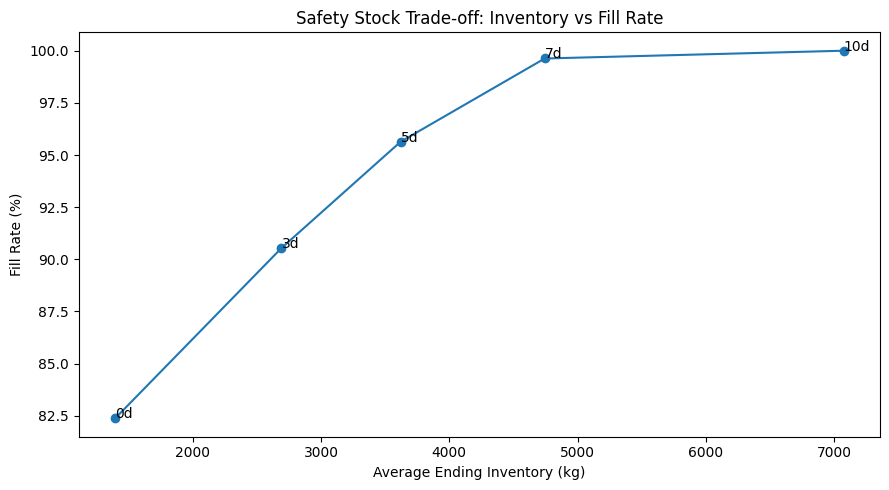

In [32]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    safety_stock_summary[
        "avg_ending_inventory_kg"
    ],
    safety_stock_summary[
        "fill_rate_pct"
    ],
    marker="o"
)

for _, row in safety_stock_summary.iterrows():

    plt.annotate(
        f'{int(row["safety_stock_days"])}d',
        (
            row[
                "avg_ending_inventory_kg"
            ],
            row[
                "fill_rate_pct"
            ],
        )
    )

plt.title(
    "Safety Stock Trade-off: Inventory vs Fill Rate"
)

plt.xlabel(
    "Average Ending Inventory (kg)"
)

plt.ylabel(
    "Fill Rate (%)"
)

plt.tight_layout()
plt.show()

In [33]:
baseline_result = (
    simulate_inventory_policy(
        sim_df=sim,
        policy_name="Baseline",
        use_risk_buffer=False,
    )
)


risk_aware_result = (
    simulate_inventory_policy(
        sim_df=sim,
        policy_name="Risk-aware",
        use_risk_buffer=True,
    )
)

In [34]:
simulation_result = pd.concat(
    [
        baseline_result,
        risk_aware_result,
    ],
    ignore_index=True
)

In [35]:
print(
    "Baseline rows:",
    len(baseline_result)
)

print(
    "Risk-aware rows:",
    len(risk_aware_result)
)

print(
    "Total rows:",
    len(simulation_result)
)

Baseline rows: 52
Risk-aware rows: 52
Total rows: 104


In [36]:
policy_summary = (
    simulation_result
    .groupby("policy")
    .apply(
        summarize_policy,
        include_groups=False
    )
)

policy_summary

,weeks,stockout_weeks,stockout_rate_pct,total_demand_kg,fulfilled_demand_kg,lost_sales_kg,fill_rate_pct,avg_ending_inventory_kg,avg_days_of_cover,total_order_qty_kg,order_weeks,avg_order_qty_kg
policy,,,,,,,,,,,,
Baseline,52.000,9.000,17.308,"292,402.064","264,734.042","27,668.022",90.538,"2,691.508",3.390,"262,000.000",46.000,"5,695.652"
Risk-aware,52.000,9.000,17.308,"292,402.064","264,734.042","27,668.022",90.538,"2,845.354",3.595,"262,500.000",46.000,"5,706.522"


In [37]:
baseline_kpi = (
    policy_summary.loc[
        "Baseline"
    ]
)

risk_kpi = (
    policy_summary.loc[
        "Risk-aware"
    ]
)


comparison = pd.DataFrame({

    "Baseline":
        baseline_kpi,

    "Risk-aware":
        risk_kpi,

})

comparison["Difference"] = (
    comparison["Risk-aware"]
    - comparison["Baseline"]
)

comparison

,Baseline,Risk-aware,Difference
weeks,52.000,52.000,0.000
stockout_weeks,9.000,9.000,0.000
stockout_rate_pct,17.308,17.308,0.000
total_demand_kg,"292,402.064","292,402.064",0.000
fulfilled_demand_kg,"264,734.042","264,734.042",0.000
lost_sales_kg,"27,668.022","27,668.022",-0.000
fill_rate_pct,90.538,90.538,0.000
avg_ending_inventory_kg,"2,691.508","2,845.354",153.846
avg_days_of_cover,3.390,3.595,0.204
total_order_qty_kg,"262,000.000","262,500.000",500.000


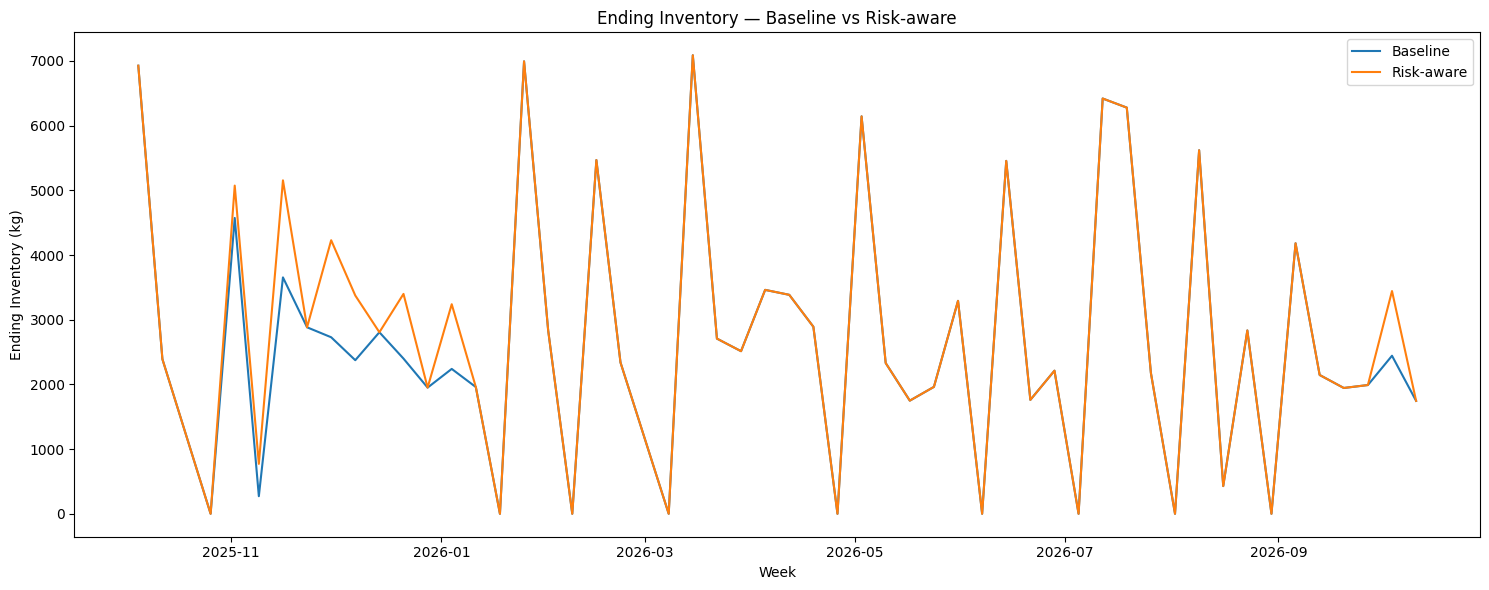

In [38]:
plt.figure(
    figsize=(15, 6)
)

plt.plot(
    baseline_result[
        "target_week"
    ],
    baseline_result[
        "ending_inventory_kg"
    ],
    label="Baseline",
)

plt.plot(
    risk_aware_result[
        "target_week"
    ],
    risk_aware_result[
        "ending_inventory_kg"
    ],
    label="Risk-aware",
)

plt.title(
    "Ending Inventory — Baseline vs Risk-aware"
)

plt.xlabel(
    "Week"
)

plt.ylabel(
    "Ending Inventory (kg)"
)

plt.legend()

plt.tight_layout()

plt.show()

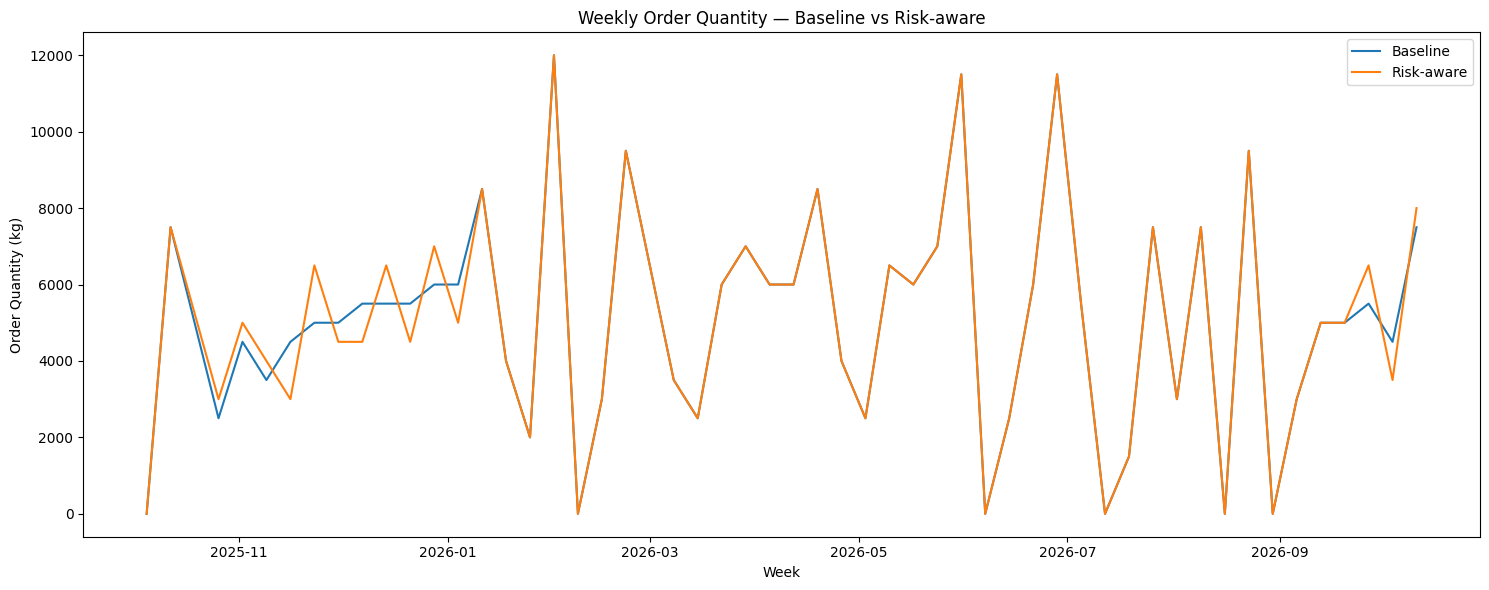

In [39]:
plt.figure(
    figsize=(15, 6)
)

plt.plot(
    baseline_result[
        "target_week"
    ],
    baseline_result[
        "order_qty_kg"
    ],
    label="Baseline",
)

plt.plot(
    risk_aware_result[
        "target_week"
    ],
    risk_aware_result[
        "order_qty_kg"
    ],
    label="Risk-aware",
)

plt.title(
    "Weekly Order Quantity — Baseline vs Risk-aware"
)

plt.xlabel(
    "Week"
)

plt.ylabel(
    "Order Quantity (kg)"
)

plt.legend()

plt.tight_layout()

plt.show()

## Weekly Policy Difference Analysis

Aggregate KPI만으로는 Risk-aware Policy가
어느 시점에서 Baseline과 다른 의사결정을 했는지 확인하기 어렵다.

따라서 동일 주차의 두 정책을 직접 비교하여

- 발주 시점 변화
- 발주량 변화
- 재고 변화
- Lost Sales 감소
- Stockout 회피 여부

를 확인한다.

In [40]:
weekly_compare = (
    baseline_result
    .merge(
        risk_aware_result,
        on="target_week",
        suffixes=("_baseline", "_risk")
    )
    .sort_values("target_week")
    .reset_index(drop=True)
)

In [41]:
weekly_compare["order_diff_kg"] = (
    weekly_compare["order_qty_kg_risk"]
    - weekly_compare["order_qty_kg_baseline"]
)

weekly_compare["ending_inventory_diff_kg"] = (
    weekly_compare["ending_inventory_kg_risk"]
    - weekly_compare["ending_inventory_kg_baseline"]
)

weekly_compare["lost_sales_reduction_kg"] = (
    weekly_compare["lost_sales_kg_baseline"]
    - weekly_compare["lost_sales_kg_risk"]
)

weekly_compare["stockout_avoided"] = (
    (
        weekly_compare["stockout_flag_baseline"] == 1
    )
    &
    (
        weekly_compare["stockout_flag_risk"] == 0
    )
).astype(int)

In [42]:
policy_change_weeks = (
    weekly_compare[
        (
            weekly_compare["order_diff_kg"] != 0
        )
        |
        (
            weekly_compare["ending_inventory_diff_kg"] != 0
        )
        |
        (
            weekly_compare["lost_sales_reduction_kg"] != 0
        )
    ][
        [
            "target_week",

            "current_risk_level_risk",
            "forecast_risk_level_risk",
            "risk_buffer_days_risk",

            "order_qty_kg_baseline",
            "order_qty_kg_risk",
            "order_diff_kg",

            "ending_inventory_kg_baseline",
            "ending_inventory_kg_risk",
            "ending_inventory_diff_kg",

            "lost_sales_kg_baseline",
            "lost_sales_kg_risk",
            "lost_sales_reduction_kg",

            "stockout_flag_baseline",
            "stockout_flag_risk",
            "stockout_avoided",
        ]
    ]
    .reset_index(drop=True)
)

policy_change_weeks

,target_week,current_risk_level_risk,forecast_risk_level_risk,risk_buffer_days_risk,order_qty_kg_baseline,order_qty_kg_risk,order_diff_kg,ending_inventory_kg_baseline,ending_inventory_kg_risk,ending_inventory_diff_kg,lost_sales_kg_baseline,lost_sales_kg_risk,lost_sales_reduction_kg,stockout_flag_baseline,stockout_flag_risk,stockout_avoided
0,2025-10-26,Watch,Watch,1,"2,500.000","3,000.000",500.000,0.000,0.000,0.000,"2,914.603","2,914.603",0.000,1,1,0
1,2025-11-02,Watch,Watch,1,"4,500.000","5,000.000",500.000,"4,573.286","5,073.286",500.000,0.000,0.000,0.000,0,0,0
2,2025-11-09,Normal,Watch,2,"3,500.000","4,000.000",500.000,271.840,771.840,500.000,0.000,0.000,0.000,0,0,0
3,2025-11-16,Risk,Watch,0,"4,500.000","3,000.000","-1,500.000","3,654.412","5,154.412","1,500.000",0.000,0.000,0.000,0,0,0
4,2025-11-23,Normal,Watch,2,"5,000.000","6,500.000","1,500.000","2,882.784","2,882.784",0.000,0.000,0.000,0.000,0,0,0
5,2025-11-30,Watch,Watch,1,"5,000.000","4,500.000",-500.000,"2,728.853","4,228.853","1,500.000",0.000,0.000,0.000,0,0,0
6,2025-12-07,Normal,Normal,0,"5,500.000","4,500.000","-1,000.000","2,374.354","3,374.354","1,000.000",0.000,0.000,0.000,0,0,0
7,2025-12-14,Watch,Watch,1,"5,500.000","6,500.000","1,000.000","2,806.363","2,806.363",0.000,0.000,0.000,0.000,0,0,0
8,2025-12-21,Normal,Normal,0,"5,500.000","4,500.000","-1,000.000","2,399.092","3,399.092","1,000.000",0.000,0.000,0.000,0,0,0
9,2025-12-28,Watch,Watch,1,"6,000.000","7,000.000","1,000.000","1,950.641","1,950.641",0.000,0.000,0.000,0.000,0,0,0


In [43]:
buffer_weeks = (
    weekly_compare[
        weekly_compare[
            "risk_buffer_days_risk"
        ] > 0
    ][
        [
            "target_week",

            "current_price_index_risk",
            "predicted_price_index_risk",

            "current_risk_level_risk",
            "forecast_risk_level_risk",

            "risk_buffer_days_risk",

            "inventory_position_kg_baseline",
            "inventory_position_kg_risk",

            "target_inventory_qty_kg_baseline",
            "target_inventory_qty_kg_risk",

            "order_qty_kg_baseline",
            "order_qty_kg_risk",

            "ending_inventory_kg_baseline",
            "ending_inventory_kg_risk",

            "lost_sales_kg_baseline",
            "lost_sales_kg_risk",
        ]
    ]
    .reset_index(drop=True)
)

buffer_weeks

,target_week,current_price_index_risk,predicted_price_index_risk,current_risk_level_risk,forecast_risk_level_risk,risk_buffer_days_risk,inventory_position_kg_baseline,inventory_position_kg_risk,target_inventory_qty_kg_baseline,target_inventory_qty_kg_risk,order_qty_kg_baseline,order_qty_kg_risk,ending_inventory_kg_baseline,ending_inventory_kg_risk,lost_sales_kg_baseline,lost_sales_kg_risk
0,2025-10-26,1.101,1.097,Watch,Watch,1,"9,890.849","9,890.849","12,154.936","12,869.932","2,500.000","3,000.000",0.000,0.000,"2,914.603","2,914.603"
1,2025-11-02,1.095,1.102,Watch,Watch,1,"10,000.000","10,500.000","14,419.871","15,140.865","4,500.000","5,000.000","4,573.286","5,073.286",0.000,0.000
2,2025-11-09,0.957,1.057,Normal,Watch,2,"9,073.286","10,073.286","12,378.430","13,834.716","3,500.000","4,000.000",271.840,771.840,0.000,0.000
3,2025-11-23,0.953,1.070,Normal,Watch,2,"8,154.412","8,154.412","12,672.918","14,163.850","5,000.000","6,500.000","2,882.784","2,882.784",0.000,0.000
4,2025-11-30,1.092,1.080,Watch,Watch,1,"7,882.784","9,382.784","12,841.572","13,596.958","5,000.000","4,500.000","2,728.853","4,228.853",0.000,0.000
5,2025-12-14,1.096,1.073,Watch,Watch,1,"7,874.354","7,874.354","13,209.437","13,986.463","5,500.000","6,500.000","2,806.363","2,806.363",0.000,0.000
6,2025-12-28,1.082,1.060,Watch,Watch,1,"7,899.092","7,899.092","13,600.000","14,400.000","6,000.000","7,000.000","1,950.641","1,950.641",0.000,0.000
7,2026-09-27,1.040,1.102,Normal,Watch,2,"6,944.887","6,944.887","11,968.000","13,376.000","5,500.000","6,500.000","1,990.245","1,990.245",0.000,0.000
8,2026-10-11,1.138,1.128,Watch,Watch,1,"6,943.249","6,943.249","14,135.792","14,842.581","7,500.000","8,000.000","1,745.857","1,745.857",0.000,0.000


In [44]:
baseline_stockout_weeks = (
    baseline_result[
        baseline_result[
            "stockout_flag"
        ] == 1
    ][
        [
            "target_week",

            "beginning_inventory_kg",
            "inbound_qty_kg",
            "open_order_qty_kg",

            "forecast_weekly_demand_kg",
            "actual_weekly_demand_kg",

            "lead_time_days",
            "lead_time_weeks",

            "target_days",
            "target_inventory_qty_kg",

            "order_qty_kg",

            "lost_sales_kg",
            "ending_inventory_kg",

            "current_price_index",
            "predicted_price_index",
        ]
    ]
    .reset_index(drop=True)
)

baseline_stockout_weeks

,target_week,beginning_inventory_kg,inbound_qty_kg,open_order_qty_kg,forecast_weekly_demand_kg,actual_weekly_demand_kg,lead_time_days,lead_time_weeks,target_days,target_inventory_qty_kg,order_qty_kg,lost_sales_kg,ending_inventory_kg,current_price_index,predicted_price_index
0,2025-10-26,"2,390.849",0.000,"7,500.000","5,004.974","5,305.453",7,1,17,"12,154.936","2,500.000","2,914.603",0.000,1.101,1.097
1,2026-01-18,"1,959.304",0.000,"8,500.000","5,838.294","6,056.651",7,1,17,"14,178.715","4,000.000","4,097.347",0.000,1.005,0.990
2,2026-02-08,"2,835.936",0.000,"12,000.000","6,045.618","5,581.855",7,1,17,"14,682.216",0.000,"2,745.919",0.000,0.917,0.954
3,2026-03-08,"2,339.637",0.000,"9,500.000","6,228.331","6,136.220",7,1,17,"15,125.947","3,500.000","3,796.583",0.000,1.053,0.956
4,2026-04-26,"2,891.370",0.000,"8,500.000","6,195.026","6,376.141",7,1,17,"15,045.064","4,000.000","3,484.771",0.000,0.962,0.949
5,2026-06-07,"3,291.756",0.000,"11,500.000","5,838.294","5,458.211",7,1,17,"14,178.715",0.000,"2,166.455",0.000,0.701,0.750
6,2026-07-05,"2,212.249",0.000,"11,500.000","5,518.999","5,148.054",14,2,24,"18,922.283","5,500.000","2,935.805",0.000,0.883,0.937
7,2026-08-02,"2,176.697",0.000,"7,500.000","5,218.260","5,445.006",7,1,17,"12,672.918","3,000.000","3,268.309",0.000,1.158,1.056
8,2026-08-30,"2,834.307",0.000,"9,500.000","5,004.974","5,092.536",7,1,17,"12,154.936",0.000,"2,258.229",0.000,1.312,1.200


In [45]:
baseline_stockout_weeks[
    "forecast_error_pct"
] = (
    (
        baseline_stockout_weeks[
            "actual_weekly_demand_kg"
        ]
        -
        baseline_stockout_weeks[
            "forecast_weekly_demand_kg"
        ]
    )
    /
    baseline_stockout_weeks[
        "forecast_weekly_demand_kg"
    ]
    * 100
)

baseline_stockout_weeks[
    [
        "target_week",
        "lead_time_days",
        "forecast_weekly_demand_kg",
        "actual_weekly_demand_kg",
        "forecast_error_pct",
        "beginning_inventory_kg",
        "inbound_qty_kg",
        "order_qty_kg",
        "lost_sales_kg",
    ]
]

,target_week,lead_time_days,forecast_weekly_demand_kg,actual_weekly_demand_kg,forecast_error_pct,beginning_inventory_kg,inbound_qty_kg,order_qty_kg,lost_sales_kg
0,2025-10-26,7,"5,004.974","5,305.453",6.004,"2,390.849",0.000,"2,500.000","2,914.603"
1,2026-01-18,7,"5,838.294","6,056.651",3.740,"1,959.304",0.000,"4,000.000","4,097.347"
2,2026-02-08,7,"6,045.618","5,581.855",-7.671,"2,835.936",0.000,0.000,"2,745.919"
3,2026-03-08,7,"6,228.331","6,136.220",-1.479,"2,339.637",0.000,"3,500.000","3,796.583"
4,2026-04-26,7,"6,195.026","6,376.141",2.924,"2,891.370",0.000,"4,000.000","3,484.771"
5,2026-06-07,7,"5,838.294","5,458.211",-6.510,"3,291.756",0.000,0.000,"2,166.455"
6,2026-07-05,14,"5,518.999","5,148.054",-6.721,"2,212.249",0.000,"5,500.000","2,935.805"
7,2026-08-02,7,"5,218.260","5,445.006",4.345,"2,176.697",0.000,"3,000.000","3,268.309"
8,2026-08-30,7,"5,004.974","5,092.536",1.750,"2,834.307",0.000,0.000,"2,258.229"


In [46]:
stockout_pattern = baseline_result[
    [
        "target_week",
        "stockout_flag",
        "lost_sales_kg",
        "lead_time_days",
    ]
].copy()

stockout_pattern["stockout_group"] = (
    stockout_pattern["stockout_flag"]
    .ne(
        stockout_pattern[
            "stockout_flag"
        ].shift()
    )
    .cumsum()
)

stockout_pattern[
    stockout_pattern["stockout_flag"] == 1
]

,target_week,stockout_flag,lost_sales_kg,lead_time_days,stockout_group
2,2025-10-26,1,"2,914.603",7,2
14,2026-01-18,1,"4,097.347",7,4
17,2026-02-08,1,"2,745.919",7,6
20,2026-03-08,1,"3,796.583",7,8
27,2026-04-26,1,"3,484.771",7,10
33,2026-06-07,1,"2,166.455",7,12
37,2026-07-05,1,"2,935.805",14,14
41,2026-08-02,1,"3,268.309",7,16
45,2026-08-30,1,"2,258.229",7,18


## Price Risk Policy Evaluation

Safety Stock 민감도 분석 결과,
7일 Safety Stock에서 Fill Rate 99% 이상을 확보하면서
10일 정책 대비 재고 증가 부담을 크게 낮출 수 있었다.

따라서 Safety Stock 7일을 본 Simulation의 Working Baseline으로 설정한다.

이후 동일한 Safety Stock 조건에서

- Baseline Replenishment Policy
- Price Risk-aware Advance Purchase Policy

를 비교한다.

이를 통해 재고 안정성 자체가 아니라,
Price Risk Signal이 발주 시점과 재고 보유에 어떤 영향을 주는지 분리하여 평가한다.

In [47]:
WORKING_SAFETY_STOCK_DAYS = 7

In [48]:
baseline_7d = simulate_inventory_policy(
    sim_df=sim,
    policy_name="Baseline_7d",
    use_risk_buffer=False,
    safety_stock_days=WORKING_SAFETY_STOCK_DAYS,
)

risk_aware_7d = simulate_inventory_policy(
    sim_df=sim,
    policy_name="Risk-aware_7d",
    use_risk_buffer=True,
    safety_stock_days=WORKING_SAFETY_STOCK_DAYS,
)

In [49]:
simulation_7d = pd.concat(
    [
        baseline_7d,
        risk_aware_7d,
    ],
    ignore_index=True
)

In [50]:
policy_summary_7d = (
    simulation_7d
    .groupby("policy")
    .apply(
        summarize_policy,
        include_groups=False
    )
)

policy_summary_7d

,weeks,stockout_weeks,stockout_rate_pct,total_demand_kg,fulfilled_demand_kg,lost_sales_kg,fill_rate_pct,avg_ending_inventory_kg,avg_days_of_cover,total_order_qty_kg,order_weeks,avg_order_qty_kg
policy,,,,,,,,,,,,
Baseline_7d,52.000,4.000,7.692,"292,402.064","291,311.071","1,090.993",99.627,"4,744.019",5.971,"288,500.000",47.000,"6,138.298"
Risk-aware_7d,52.000,4.000,7.692,"292,402.064","291,311.071","1,090.993",99.627,"4,917.096",6.203,"289,000.000",47.000,"6,148.936"


In [51]:
comparison_7d = pd.DataFrame({
    "Baseline_7d":
        policy_summary_7d.loc["Baseline_7d"],

    "Risk-aware_7d":
        policy_summary_7d.loc["Risk-aware_7d"],
})

comparison_7d["Difference"] = (
    comparison_7d["Risk-aware_7d"]
    - comparison_7d["Baseline_7d"]
)

comparison_7d

,Baseline_7d,Risk-aware_7d,Difference
weeks,52.000,52.000,0.000
stockout_weeks,4.000,4.000,0.000
stockout_rate_pct,7.692,7.692,0.000
total_demand_kg,"292,402.064","292,402.064",0.000
fulfilled_demand_kg,"291,311.071","291,311.071",0.000
lost_sales_kg,"1,090.993","1,090.993",0.000
fill_rate_pct,99.627,99.627,0.000
avg_ending_inventory_kg,"4,744.019","4,917.096",173.077
avg_days_of_cover,5.971,6.203,0.232
total_order_qty_kg,"288,500.000","289,000.000",500.000


In [52]:
weekly_compare_7d = (
    baseline_7d
    .merge(
        risk_aware_7d,
        on="target_week",
        suffixes=("_baseline", "_risk")
    )
    .sort_values("target_week")
    .reset_index(drop=True)
)

In [53]:
weekly_compare_7d["order_diff_kg"] = (
    weekly_compare_7d["order_qty_kg_risk"]
    - weekly_compare_7d["order_qty_kg_baseline"]
)

weekly_compare_7d["inventory_diff_kg"] = (
    weekly_compare_7d["ending_inventory_kg_risk"]
    - weekly_compare_7d["ending_inventory_kg_baseline"]
)

In [54]:
risk_action_weeks = (
    weekly_compare_7d[
        weekly_compare_7d[
            "risk_buffer_days_risk"
        ] > 0
    ][
        [
            "target_week",

            "current_risk_level_risk",
            "forecast_risk_level_risk",
            "risk_buffer_days_risk",

            "current_price_index_risk",
            "predicted_price_index_risk",

            "order_qty_kg_baseline",
            "order_qty_kg_risk",
            "order_diff_kg",

            "ending_inventory_kg_baseline",
            "ending_inventory_kg_risk",
            "inventory_diff_kg",
        ]
    ]
    .reset_index(drop=True)
)

risk_action_weeks

,target_week,current_risk_level_risk,forecast_risk_level_risk,risk_buffer_days_risk,current_price_index_risk,predicted_price_index_risk,order_qty_kg_baseline,order_qty_kg_risk,order_diff_kg,ending_inventory_kg_baseline,ending_inventory_kg_risk,inventory_diff_kg
0,2025-10-26,Watch,Watch,1,1.101,1.097,"2,500.000","3,500.000","1,000.000",0.000,0.000,0.000
1,2025-11-02,Watch,Watch,1,1.095,1.102,"7,500.000","7,500.000",0.000,"4,573.286","5,573.286","1,000.000"
2,2025-11-09,Normal,Watch,2,0.957,1.057,"3,500.000","4,000.000",500.000,271.840,"1,271.840","1,000.000"
3,2025-11-23,Normal,Watch,2,0.953,1.070,"5,000.000","6,000.000","1,000.000","5,882.784","5,882.784",0.000
4,2025-11-30,Watch,Watch,1,1.092,1.080,"5,000.000","5,000.000",0.000,"5,728.853","6,728.853","1,000.000"
5,2025-12-14,Watch,Watch,1,1.096,1.073,"5,500.000","6,500.000","1,000.000","5,806.363","5,806.363",0.000
6,2025-12-28,Watch,Watch,1,1.082,1.060,"6,000.000","7,000.000","1,000.000","4,950.641","4,950.641",0.000
7,2026-09-27,Normal,Watch,2,1.040,1.102,"5,500.000","7,000.000","1,500.000","4,732.016","4,732.016",0.000
8,2026-10-11,Watch,Watch,1,1.138,1.128,"7,000.000","7,500.000",500.000,"4,987.628","4,987.628",0.000


In [55]:
advance_order_kg = (
    weekly_compare_7d.loc[
        weekly_compare_7d["order_diff_kg"] > 0,
        "order_diff_kg"
    ]
    .sum()
)

deferred_reduction_kg = (
    -weekly_compare_7d.loc[
        weekly_compare_7d["order_diff_kg"] < 0,
        "order_diff_kg"
    ]
    .sum()
)

net_order_change_kg = (
    risk_aware_7d["order_qty_kg"].sum()
    -
    baseline_7d["order_qty_kg"].sum()
)

print(
    f"Advance order volume: "
    f"{advance_order_kg:,.0f} kg"
)

print(
    f"Later order reduction: "
    f"{deferred_reduction_kg:,.0f} kg"
)

print(
    f"Net order change: "
    f"{net_order_change_kg:,.0f} kg"
)

Advance order volume: 6,500 kg
Later order reduction: 6,000 kg
Net order change: 500 kg


In [56]:
weekly_compare_7d["cumulative_order_baseline"] = (
    weekly_compare_7d[
        "order_qty_kg_baseline"
    ]
    .cumsum()
)

weekly_compare_7d["cumulative_order_risk"] = (
    weekly_compare_7d[
        "order_qty_kg_risk"
    ]
    .cumsum()
)

weekly_compare_7d["cumulative_order_diff_kg"] = (
    weekly_compare_7d[
        "cumulative_order_risk"
    ]
    -
    weekly_compare_7d[
        "cumulative_order_baseline"
    ]
)

In [57]:
def get_risk_buffer_days(row):

    current = row["current_risk_level"]
    forecast = row["forecast_risk_level"]

    # ---------------------------------------------
    # 1. Normal → Watch
    # 실제 Early Warning
    # ---------------------------------------------

    if (
        current == "Normal"
        and forecast == "Watch"
    ):
        return 2


    # ---------------------------------------------
    # 2. Normal → Risk
    # 강한 신규 Risk 진입 예측
    # ---------------------------------------------

    if (
        current == "Normal"
        and forecast == "Risk"
    ):
        return 4


    # ---------------------------------------------
    # 3. Watch → Risk
    # Risk Escalation
    # ---------------------------------------------

    if (
        current == "Watch"
        and forecast == "Risk"
    ):
        return 3


    # ---------------------------------------------
    # 그 외
    # Watch Persistence / Risk Persistence /
    # Easing 상태에서는 선행구매하지 않음
    # ---------------------------------------------

    return 0

In [58]:
sim["risk_buffer_days"] = (
    sim.apply(
        get_risk_buffer_days,
        axis=1
    )
)

sim["risk_buffer_days"].value_counts()

risk_buffer_days
0    49
2     3
Name: count, dtype: int64

In [59]:
baseline_7d = simulate_inventory_policy(
    sim_df=sim,
    policy_name="Baseline_7d",
    use_risk_buffer=False,
    safety_stock_days=7,
)

risk_aware_7d = simulate_inventory_policy(
    sim_df=sim,
    policy_name="Risk-aware_7d",
    use_risk_buffer=True,
    safety_stock_days=7,
)

In [60]:
simulation_7d = pd.concat(
    [
        baseline_7d,
        risk_aware_7d,
    ],
    ignore_index=True
)

policy_summary_7d = (
    simulation_7d
    .groupby("policy")
    .apply(
        summarize_policy,
        include_groups=False
    )
)

policy_summary_7d

,weeks,stockout_weeks,stockout_rate_pct,total_demand_kg,fulfilled_demand_kg,lost_sales_kg,fill_rate_pct,avg_ending_inventory_kg,avg_days_of_cover,total_order_qty_kg,order_weeks,avg_order_qty_kg
policy,,,,,,,,,,,,
Baseline_7d,52.000,4.000,7.692,"292,402.064","291,311.071","1,090.993",99.627,"4,744.019",5.971,"288,500.000",47.000,"6,138.298"
Risk-aware_7d,52.000,4.000,7.692,"292,402.064","291,311.071","1,090.993",99.627,"4,820.942",6.077,"288,500.000",47.000,"6,138.298"


In [61]:
weekly_compare_7d = (
    baseline_7d
    .merge(
        risk_aware_7d,
        on="target_week",
        suffixes=("_baseline", "_risk")
    )
    .sort_values("target_week")
    .reset_index(drop=True)
)

weekly_compare_7d["order_diff_kg"] = (
    weekly_compare_7d["order_qty_kg_risk"]
    - weekly_compare_7d["order_qty_kg_baseline"]
)

weekly_compare_7d["inventory_diff_kg"] = (
    weekly_compare_7d["ending_inventory_kg_risk"]
    - weekly_compare_7d["ending_inventory_kg_baseline"]
)

In [62]:
risk_action_weeks = (
    weekly_compare_7d[
        weekly_compare_7d[
            "risk_buffer_days_risk"
        ] > 0
    ][
        [
            "target_week",

            "current_risk_level_risk",
            "forecast_risk_level_risk",
            "risk_buffer_days_risk",

            "current_price_index_risk",
            "predicted_price_index_risk",
            "actual_price_index_risk",

            "order_qty_kg_baseline",
            "order_qty_kg_risk",
            "order_diff_kg",

            "ending_inventory_kg_baseline",
            "ending_inventory_kg_risk",
            "inventory_diff_kg",
        ]
    ]
    .reset_index(drop=True)
)

risk_action_weeks

,target_week,current_risk_level_risk,forecast_risk_level_risk,risk_buffer_days_risk,current_price_index_risk,predicted_price_index_risk,actual_price_index_risk,order_qty_kg_baseline,order_qty_kg_risk,order_diff_kg,ending_inventory_kg_baseline,ending_inventory_kg_risk,inventory_diff_kg
0,2025-11-09,Normal,Watch,2,0.957,1.057,1.156,"3,500.000","5,000.000","1,500.000",271.840,271.840,0.000
1,2025-11-23,Normal,Watch,2,0.953,1.070,1.092,"5,000.000","6,000.000","1,000.000","5,882.784","5,882.784",0.000
2,2026-09-27,Normal,Watch,2,1.040,1.102,1.176,"5,500.000","7,000.000","1,500.000","4,732.016","4,732.016",0.000


In [63]:
advance_order_kg = (
    weekly_compare_7d.loc[
        weekly_compare_7d["order_diff_kg"] > 0,
        "order_diff_kg"
    ]
    .sum()
)

later_order_reduction_kg = (
    -weekly_compare_7d.loc[
        weekly_compare_7d["order_diff_kg"] < 0,
        "order_diff_kg"
    ]
    .sum()
)

net_order_change_kg = (
    risk_aware_7d["order_qty_kg"].sum()
    -
    baseline_7d["order_qty_kg"].sum()
)

timing_offset_pct = (
    later_order_reduction_kg
    / advance_order_kg
    * 100
    if advance_order_kg > 0
    else np.nan
)

print(
    f"Advance order volume: "
    f"{advance_order_kg:,.0f} kg"
)

print(
    f"Later order reduction: "
    f"{later_order_reduction_kg:,.0f} kg"
)

print(
    f"Net order change: "
    f"{net_order_change_kg:,.0f} kg"
)

print(
    f"Timing offset ratio: "
    f"{timing_offset_pct:.1f}%"
)

Advance order volume: 4,000 kg
Later order reduction: 4,000 kg
Net order change: 0 kg
Timing offset ratio: 100.0%


In [64]:
risk_action_weeks[
    "actual_price_change"
] = (
    risk_action_weeks[
        "actual_price_index_risk"
    ]
    -
    risk_action_weeks[
        "current_price_index_risk"
    ]
)

risk_action_weeks[
    "actual_price_increase"
] = (
    risk_action_weeks[
        "actual_price_change"
    ] > 0
)

risk_action_weeks[
    [
        "target_week",
        "current_price_index_risk",
        "predicted_price_index_risk",
        "actual_price_index_risk",
        "actual_price_change",
        "actual_price_increase",
        "order_diff_kg",
    ]
]

,target_week,current_price_index_risk,predicted_price_index_risk,actual_price_index_risk,actual_price_change,actual_price_increase,order_diff_kg
0,2025-11-09,0.957,1.057,1.156,0.199,True,"1,500.000"
1,2025-11-23,0.953,1.070,1.092,0.139,True,"1,000.000"
2,2026-09-27,1.040,1.102,1.176,0.136,True,"1,500.000"


In [65]:
week_gap_check = (
    sim["target_week"]
    .sort_values()
    .diff()
    .dt.days
    .value_counts()
    .sort_index()
)

week_gap_check

target_week
7.000     49
14.000     2
Name: count, dtype: int64

In [66]:
# ==================================================
# Continuous Weekly Calendar
# ==================================================

calendar = pd.DataFrame({
    "target_week": pd.date_range(
        start=risk["target_week"].min(),
        end=risk["target_week"].max(),
        freq="W-SUN"
    )
})

print("OOF rows:", len(risk))
print("Calendar weeks:", len(calendar))

OOF rows: 52
Calendar weeks: 54


In [67]:
sim = (
    calendar
    .merge(
        risk,
        on="target_week",
        how="left"
    )
    .sort_values("target_week")
    .reset_index(drop=True)
)

In [68]:
print("Simulation rows:", len(sim))

print(
    sim["target_week"]
    .diff()
    .dt.days
    .value_counts()
    .sort_index()
)

Simulation rows: 54
target_week
7.000    53
Name: count, dtype: int64


In [69]:
missing_forecast_weeks = sim[
    sim["predicted_price_index"].isna()
][
    ["target_week"]
]

missing_forecast_weeks

,target_week
2,2025-10-19
21,2026-03-01


In [70]:
def classify_risk_level(price_index):

    if pd.isna(price_index):
        return np.nan

    if price_index >= 1.15:
        return "Risk"

    elif price_index >= 1.05:
        return "Watch"

    else:
        return "Normal"

In [71]:
sim["forecast_risk_level"] = (
    sim["predicted_price_index"]
    .apply(classify_risk_level)
)

In [72]:
sim["forecast_risk_level"] = (
    sim["predicted_price_index"]
    .apply(classify_risk_level)
)

sim["has_price_forecast"] = (
    sim["predicted_price_index"]
    .notna()
)

In [73]:
def get_risk_buffer_days(row):

    current = row["current_risk_level"]
    forecast = row["forecast_risk_level"]

    if (
        current == "Normal"
        and forecast == "Watch"
    ):
        return 2

    if (
        current == "Normal"
        and forecast == "Risk"
    ):
        return 4

    if (
        current == "Watch"
        and forecast == "Risk"
    ):
        return 3

    return 0

In [74]:
sim["week_end_date"] = (
    sim["target_week"]
    - pd.Timedelta(days=7)
)

In [75]:
print("Simulation rows:", len(sim))

print(
    sim["target_week"]
    .diff()
    .dt.days
    .value_counts()
    .sort_index()
)

print()

print(
    sim[
        ~sim["has_price_forecast"]
    ][
        [
            "week_end_date",
            "target_week",
            "predicted_price_index",
            "forecast_risk_level",
        ]
    ]
)

Simulation rows: 54
target_week
7.000    53
Name: count, dtype: int64

   week_end_date target_week  predicted_price_index forecast_risk_level
2     2025-10-12  2025-10-19                    NaN                 NaN
21    2026-02-22  2026-03-01                    NaN                 NaN


In [76]:
sim["risk_buffer_days"] = (
    sim.apply(
        get_risk_buffer_days,
        axis=1
    )
)

sim["risk_buffer_days"].value_counts()

risk_buffer_days
0    51
2     3
Name: count, dtype: int64

In [77]:
def simulate_inventory_policy(
    sim_df,
    policy_name,
    use_risk_buffer=False,
    safety_stock_days=3,
):

    df = (
        sim_df
        .copy()
        .sort_values("target_week")
        .reset_index(drop=True)
    )

    # ---------------------------------------------
    # Simulation 기간
    # ---------------------------------------------

    simulation_end_week = (
        df["target_week"].max()
    )


    # ---------------------------------------------
    # Initial Inventory
    # ---------------------------------------------

    initial_daily_demand = (
        df.loc[
            0,
            "forecast_daily_demand_kg"
        ]
    )

    initial_lead_days = (
        df.loc[
            0,
            "lead_time_days"
        ]
    )

    initial_target_days = (
        initial_lead_days
        + REVIEW_PERIOD_DAYS
        + safety_stock_days
    )

    on_hand = (
        initial_daily_demand
        * initial_target_days
    )


    # key = 실제 입고 예정 주차(Timestamp)
    # value = 입고 예정 수량
    scheduled_receipts = {}

    records = []


    # =============================================
    # Weekly Simulation
    # =============================================

    for idx, row in df.iterrows():

        current_week = (
            row["target_week"]
        )


        # -----------------------------------------
        # 1. 이번 주 도착 물량
        # -----------------------------------------

        inbound_qty = (
            scheduled_receipts.pop(
                current_week,
                0.0
            )
        )

        beginning_inventory = (
            on_hand
            + inbound_qty
        )


        # -----------------------------------------
        # 2. 아직 도착하지 않은 Open Orders
        # -----------------------------------------

        open_order_qty = (
            sum(
                scheduled_receipts.values()
            )
        )

        inventory_position = (
            beginning_inventory
            + open_order_qty
        )


        # -----------------------------------------
        # 3. Risk Buffer
        # -----------------------------------------

        if use_risk_buffer:

            risk_buffer_days = (
                row["risk_buffer_days"]
            )

        else:

            risk_buffer_days = 0


        # -----------------------------------------
        # 4. Target Inventory
        # -----------------------------------------

        target_days = (
            row["lead_time_days"]
            + REVIEW_PERIOD_DAYS
            + safety_stock_days
            + risk_buffer_days
        )

        target_inventory_qty = (
            row["forecast_daily_demand_kg"]
            * target_days
        )


        # -----------------------------------------
        # 5. Order Decision
        # -----------------------------------------

        raw_order_qty = max(
            0,
            target_inventory_qty
            - inventory_position
        )

        order_qty = round_up_to_moq(
            raw_order_qty
        )


        # -----------------------------------------
        # 6. 실제 날짜 기준 입고 예정 등록
        # -----------------------------------------

        lead_weeks = int(
            row["lead_time_weeks"]
        )

        arrival_week = (
            current_week
            + pd.Timedelta(
                weeks=lead_weeks
            )
        )

        if (
            order_qty > 0
            and arrival_week <= simulation_end_week
        ):

            scheduled_receipts[
                arrival_week
            ] = (
                scheduled_receipts.get(
                    arrival_week,
                    0.0
                )
                + order_qty
            )


        # -----------------------------------------
        # 7. Actual Demand 발생
        # -----------------------------------------

        actual_demand = (
            row[
                "actual_weekly_demand_kg"
            ]
        )

        fulfilled_demand = min(
            beginning_inventory,
            actual_demand
        )

        lost_sales = max(
            0,
            actual_demand
            - beginning_inventory
        )

        ending_inventory = max(
            0,
            beginning_inventory
            - actual_demand
        )


        # -----------------------------------------
        # 8. KPI
        # -----------------------------------------

        fill_rate = (
            fulfilled_demand
            / actual_demand
            if actual_demand > 0
            else 1.0
        )

        ending_days_of_cover = (
            ending_inventory
            / row[
                "forecast_daily_demand_kg"
            ]
        )


        # -----------------------------------------
        # 9. 저장
        # -----------------------------------------

        records.append({

            "policy":
                policy_name,

            "week_end_date":
                row["week_end_date"],

            "target_week":
                current_week,

            "beginning_inventory_kg":
                beginning_inventory,

            "inbound_qty_kg":
                inbound_qty,

            "open_order_qty_kg":
                open_order_qty,

            "inventory_position_kg":
                inventory_position,

            "forecast_weekly_demand_kg":
                row[
                    "forecast_weekly_demand_kg"
                ],

            "actual_weekly_demand_kg":
                actual_demand,

            "target_days":
                target_days,

            "target_inventory_qty_kg":
                target_inventory_qty,

            "order_qty_kg":
                order_qty,

            "fulfilled_demand_kg":
                fulfilled_demand,

            "lost_sales_kg":
                lost_sales,

            "ending_inventory_kg":
                ending_inventory,

            "ending_days_of_cover":
                ending_days_of_cover,

            "fill_rate":
                fill_rate,

            "stockout_flag":
                int(
                    lost_sales > 0
                ),

            "lead_time_days":
                row["lead_time_days"],

            "lead_time_weeks":
                lead_weeks,

            "risk_buffer_days":
                risk_buffer_days,

            "current_price_index":
                row[
                    "current_price_index"
                ],

            "predicted_price_index":
                row[
                    "predicted_price_index"
                ],

            "actual_price_index":
                row[
                    "actual_price_index"
                ],

            "current_risk_level":
                row[
                    "current_risk_level"
                ],

            "forecast_risk_level":
                row[
                    "forecast_risk_level"
                ],

            "has_price_forecast":
                row[
                    "has_price_forecast"
                ],
        })


        # -----------------------------------------
        # 10. 다음 주로 Ending Inventory 이월
        # -----------------------------------------

        on_hand = (
            ending_inventory
        )


    return pd.DataFrame(
        records
    )

In [78]:
print(
    simulate_inventory_policy
)

<function simulate_inventory_policy at 0x11ef09a80>


In [79]:
SIMULATION_SEED = 42

BASE_DAILY_DEMAND_KG = 800

SAFETY_STOCK_DAYS = 3
REVIEW_PERIOD_DAYS = 7

MOQ_KG = 500

In [80]:
sim["week_of_year"] = (
    sim["target_week"]
    .dt
    .isocalendar()
    .week
    .astype(int)
)

sim["demand_season_factor"] = (
    1
    +
    0.12
    *
    np.sin(
        2
        * np.pi
        * sim["week_of_year"]
        / 52
    )
)

In [81]:
rng = np.random.default_rng(
    SIMULATION_SEED
)

In [82]:
sim["demand_noise"] = (
    rng.normal(
        loc=1.0,
        scale=0.08,
        size=len(sim)
    )
)

sim["avg_daily_demand_kg"] = (
    BASE_DAILY_DEMAND_KG
    * sim["demand_season_factor"]
    * sim["demand_noise"]
).clip(
    lower=500
)

sim["actual_weekly_demand_kg"] = (
    sim["avg_daily_demand_kg"]
    * 7
)

In [83]:
sim["forecast_daily_demand_kg"] = (
    BASE_DAILY_DEMAND_KG
    * sim["demand_season_factor"]
)

sim["forecast_weekly_demand_kg"] = (
    sim["forecast_daily_demand_kg"]
    * 7
)

In [84]:
lead_time_choices = [
    7,
    7,
    7,
    7,
    10,
    14,
]

sim["lead_time_days"] = (
    rng.choice(
        lead_time_choices,
        size=len(sim),
        replace=True
    )
)

sim["lead_time_weeks"] = (
    np.ceil(
        sim["lead_time_days"] / 7
    )
    .astype(int)
)

In [85]:
sim["forecast_risk_level"] = (
    sim["predicted_price_index"]
    .apply(classify_risk_level)
)

sim["has_price_forecast"] = (
    sim["predicted_price_index"]
    .notna()
)

In [86]:
sim["risk_buffer_days"] = (
    sim.apply(
        get_risk_buffer_days,
        axis=1
    )
)

In [87]:
required_sim_cols = [
    "target_week",
    "week_end_date",

    "forecast_daily_demand_kg",
    "forecast_weekly_demand_kg",
    "actual_weekly_demand_kg",

    "lead_time_days",
    "lead_time_weeks",

    "risk_buffer_days",

    "current_price_index",
    "predicted_price_index",
    "actual_price_index",

    "current_risk_level",
    "forecast_risk_level",

    "has_price_forecast",
]

missing_sim_cols = [
    col
    for col in required_sim_cols
    if col not in sim.columns
]

print(
    "Missing simulation columns:",
    missing_sim_cols
)

Missing simulation columns: []


In [88]:
test_result = simulate_inventory_policy(
    sim_df=sim,
    policy_name="TEST",
    use_risk_buffer=False,
    safety_stock_days=3,
)

print(
    "Rows:",
    len(test_result)
)

print(
    "Period:",
    test_result["target_week"].min(),
    "~",
    test_result["target_week"].max()
)

print()

print(
    test_result["target_week"]
    .diff()
    .dt.days
    .value_counts()
    .sort_index()
)

Rows: 54
Period: 2025-10-05 00:00:00 ~ 2026-10-11 00:00:00

target_week
7.000    53
Name: count, dtype: int64


In [89]:
safety_stock_results = []

for ss_days in [
    0,
    3,
    5,
    7,
    10,
]:

    result = simulate_inventory_policy(
        sim_df=sim,
        policy_name=f"SS_{ss_days}d",
        use_risk_buffer=False,
        safety_stock_days=ss_days,
    )

    summary = summarize_policy(
        result
    )

    safety_stock_results.append({
        "safety_stock_days":
            ss_days,

        "stockout_weeks":
            summary["stockout_weeks"],

        "stockout_rate_pct":
            summary["stockout_rate_pct"],

        "lost_sales_kg":
            summary["lost_sales_kg"],

        "fill_rate_pct":
            summary["fill_rate_pct"],

        "avg_ending_inventory_kg":
            summary["avg_ending_inventory_kg"],

        "avg_days_of_cover":
            summary["avg_days_of_cover"],

        "total_order_qty_kg":
            summary["total_order_qty_kg"],
    })

In [90]:
safety_stock_summary = pd.DataFrame(
    safety_stock_results
)

baseline_ss = (
    safety_stock_summary[
        safety_stock_summary[
            "safety_stock_days"
        ] == 3
    ]
    .iloc[0]
)

safety_stock_summary[
    "inventory_change_vs_3d_pct"
] = (
    (
        safety_stock_summary[
            "avg_ending_inventory_kg"
        ]
        -
        baseline_ss[
            "avg_ending_inventory_kg"
        ]
    )
    /
    baseline_ss[
        "avg_ending_inventory_kg"
    ]
    * 100
)

safety_stock_summary[
    "lost_sales_reduction_vs_3d_kg"
] = (
    baseline_ss[
        "lost_sales_kg"
    ]
    -
    safety_stock_summary[
        "lost_sales_kg"
    ]
)

safety_stock_summary

,safety_stock_days,stockout_weeks,stockout_rate_pct,lost_sales_kg,fill_rate_pct,avg_ending_inventory_kg,avg_days_of_cover,total_order_qty_kg,inventory_change_vs_3d_pct,lost_sales_reduction_vs_3d_kg
0,0,19.000,35.185,"51,856.775",82.880,"1,391.075",1.746,"248,500.000",-50.220,"-22,312.249"
1,3,9.000,16.667,"29,544.526",90.246,"2,794.442",3.527,"271,000.000",0.000,0.000
2,5,9.000,16.667,"14,635.126",95.168,"3,768.405",4.765,"286,000.000",34.854,"14,909.400"
3,7,5.000,9.259,"1,725.726",99.430,"4,813.983",6.086,"299,000.000",72.270,"27,818.800"
4,10,0.000,0.000,0.000,100.000,"7,146.390",9.020,"300,500.000",155.736,"29,544.526"


In [91]:
print(
    "Simulation weeks:",
    len(sim)
)

print(
    "Total simulated demand:",
    f'{sim["actual_weekly_demand_kg"].sum():,.1f} kg'
)

Simulation weeks: 54
Total simulated demand: 302,901.4 kg


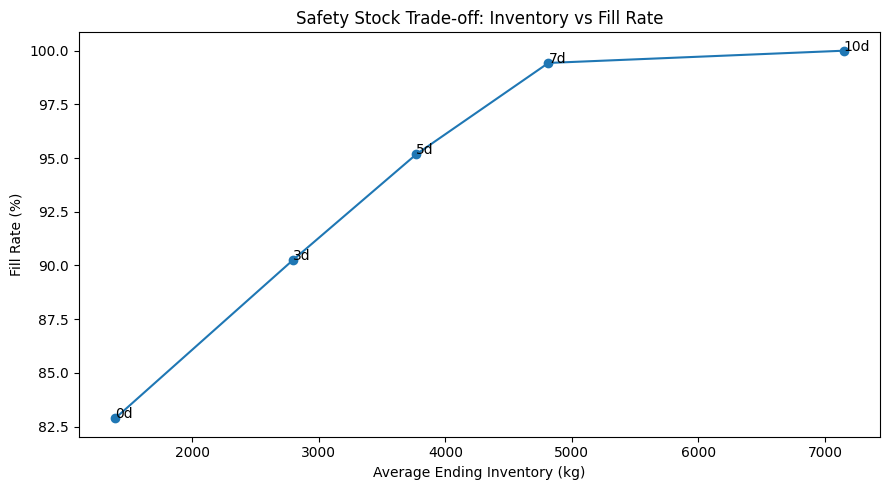

In [92]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    safety_stock_summary[
        "avg_ending_inventory_kg"
    ],
    safety_stock_summary[
        "fill_rate_pct"
    ],
    marker="o"
)

for _, row in safety_stock_summary.iterrows():

    plt.annotate(
        f'{int(row["safety_stock_days"])}d',
        (
            row[
                "avg_ending_inventory_kg"
            ],
            row[
                "fill_rate_pct"
            ],
        )
    )

plt.title(
    "Safety Stock Trade-off: Inventory vs Fill Rate"
)

plt.xlabel(
    "Average Ending Inventory (kg)"
)

plt.ylabel(
    "Fill Rate (%)"
)

plt.tight_layout()

plt.show()

## Working Safety Stock Policy

54주 연속 Calendar 기반 Safety Stock 민감도 분석 결과,
Safety Stock 증가에 따라 Service Level은 개선되었으나
재고 보유량 역시 증가하였다.

특히 5일에서 7일로 확대할 경우

- Fill Rate: 95.17% → 99.43%
- Stockout Weeks: 9 → 4
- Lost Sales: 14,621kg → 1,713kg

으로 서비스 수준이 크게 개선되었다.

반면 7일에서 10일로 확대하면
Fill Rate는 99.43%에서 100%로 소폭 개선되는 데 비해
평균 Ending Inventory는 약 48% 증가하였다.

따라서 7일을 절대적인 최적값으로 정의하지 않고,
본 Simulation에서 재고 부담과 서비스 수준 사이의
균형을 비교하기 위한 Working Safety Stock Policy로 선정한다.

In [93]:
WORKING_SAFETY_STOCK_DAYS = 7

In [94]:
baseline_7d = simulate_inventory_policy(
    sim_df=sim,
    policy_name="Baseline_7d",
    use_risk_buffer=False,
    safety_stock_days=WORKING_SAFETY_STOCK_DAYS,
)

risk_aware_7d = simulate_inventory_policy(
    sim_df=sim,
    policy_name="Risk-aware_7d",
    use_risk_buffer=True,
    safety_stock_days=WORKING_SAFETY_STOCK_DAYS,
)

In [95]:
simulation_7d = pd.concat(
    [
        baseline_7d,
        risk_aware_7d,
    ],
    ignore_index=True
)

In [96]:
policy_summary_7d = (
    simulation_7d
    .groupby("policy")
    .apply(
        summarize_policy,
        include_groups=False
    )
)

policy_summary_7d

,weeks,stockout_weeks,stockout_rate_pct,total_demand_kg,fulfilled_demand_kg,lost_sales_kg,fill_rate_pct,avg_ending_inventory_kg,avg_days_of_cover,total_order_qty_kg,order_weeks,avg_order_qty_kg
policy,,,,,,,,,,,,
Baseline_7d,54.000,5.000,9.259,"302,901.435","301,175.708","1,725.726",99.430,"4,813.983",6.086,"299,000.000",48.000,"6,229.167"
Risk-aware_7d,54.000,5.000,9.259,"302,901.435","301,175.708","1,725.726",99.430,"4,897.317",6.200,"299,000.000",48.000,"6,229.167"


In [97]:
comparison_7d = pd.DataFrame({
    "Baseline":
        policy_summary_7d.loc["Baseline_7d"],

    "Risk-aware":
        policy_summary_7d.loc["Risk-aware_7d"],
})

comparison_7d["Difference"] = (
    comparison_7d["Risk-aware"]
    - comparison_7d["Baseline"]
)

comparison_7d

,Baseline,Risk-aware,Difference
weeks,54.000,54.000,0.000
stockout_weeks,5.000,5.000,0.000
stockout_rate_pct,9.259,9.259,0.000
total_demand_kg,"302,901.435","302,901.435",0.000
fulfilled_demand_kg,"301,175.708","301,175.708",0.000
lost_sales_kg,"1,725.726","1,725.726",0.000
fill_rate_pct,99.430,99.430,0.000
avg_ending_inventory_kg,"4,813.983","4,897.317",83.333
avg_days_of_cover,6.086,6.200,0.114
total_order_qty_kg,"299,000.000","299,000.000",0.000


In [98]:
weekly_compare_7d = (
    baseline_7d
    .merge(
        risk_aware_7d,
        on="target_week",
        suffixes=("_baseline", "_risk")
    )
    .sort_values("target_week")
    .reset_index(drop=True)
)

In [99]:
weekly_compare_7d["order_diff_kg"] = (
    weekly_compare_7d["order_qty_kg_risk"]
    - weekly_compare_7d["order_qty_kg_baseline"]
)

weekly_compare_7d["inventory_diff_kg"] = (
    weekly_compare_7d["ending_inventory_kg_risk"]
    - weekly_compare_7d["ending_inventory_kg_baseline"]
)

weekly_compare_7d["lost_sales_reduction_kg"] = (
    weekly_compare_7d["lost_sales_kg_baseline"]
    - weekly_compare_7d["lost_sales_kg_risk"]
)

In [100]:
risk_action_weeks = (
    weekly_compare_7d[
        weekly_compare_7d[
            "risk_buffer_days_risk"
        ] > 0
    ][
        [
            "target_week",

            "current_price_index_risk",
            "predicted_price_index_risk",
            "actual_price_index_risk",

            "current_risk_level_risk",
            "forecast_risk_level_risk",

            "risk_buffer_days_risk",

            "order_qty_kg_baseline",
            "order_qty_kg_risk",
            "order_diff_kg",

            "ending_inventory_kg_baseline",
            "ending_inventory_kg_risk",
            "inventory_diff_kg",
        ]
    ]
    .reset_index(drop=True)
)

risk_action_weeks

,target_week,current_price_index_risk,predicted_price_index_risk,actual_price_index_risk,current_risk_level_risk,forecast_risk_level_risk,risk_buffer_days_risk,order_qty_kg_baseline,order_qty_kg_risk,order_diff_kg,ending_inventory_kg_baseline,ending_inventory_kg_risk,inventory_diff_kg
0,2025-11-09,0.957,1.057,1.156,Normal,Watch,2,"4,000.000","5,500.000","1,500.000","6,732.691","6,732.691",0.000
1,2025-11-23,0.953,1.070,1.092,Normal,Watch,2,"5,500.000","7,000.000","1,500.000","5,439.353","5,439.353",0.000
2,2026-09-27,1.040,1.102,1.176,Normal,Watch,2,"5,000.000","6,500.000","1,500.000","4,801.850","4,801.850",0.000


In [101]:
advance_order_kg = (
    weekly_compare_7d.loc[
        weekly_compare_7d["order_diff_kg"] > 0,
        "order_diff_kg"
    ]
    .sum()
)

later_order_reduction_kg = (
    -weekly_compare_7d.loc[
        weekly_compare_7d["order_diff_kg"] < 0,
        "order_diff_kg"
    ]
    .sum()
)

net_order_change_kg = (
    risk_aware_7d["order_qty_kg"].sum()
    -
    baseline_7d["order_qty_kg"].sum()
)

timing_offset_pct = (
    later_order_reduction_kg
    / advance_order_kg
    * 100
    if advance_order_kg > 0
    else np.nan
)

print(
    f"Advance order volume: "
    f"{advance_order_kg:,.0f} kg"
)

print(
    f"Later order reduction: "
    f"{later_order_reduction_kg:,.0f} kg"
)

print(
    f"Net order change: "
    f"{net_order_change_kg:,.0f} kg"
)

print(
    f"Timing offset ratio: "
    f"{timing_offset_pct:.1f}%"
)

Advance order volume: 4,500 kg
Later order reduction: 4,500 kg
Net order change: 0 kg
Timing offset ratio: 100.0%


In [102]:
risk_action_weeks[
    "actual_price_change"
] = (
    risk_action_weeks[
        "actual_price_index_risk"
    ]
    -
    risk_action_weeks[
        "current_price_index_risk"
    ]
)

risk_action_weeks[
    "actual_price_increase"
] = (
    risk_action_weeks[
        "actual_price_change"
    ] > 0
)

risk_action_weeks[
    [
        "target_week",

        "current_price_index_risk",
        "predicted_price_index_risk",
        "actual_price_index_risk",

        "actual_price_change",
        "actual_price_increase",

        "order_qty_kg_baseline",
        "order_qty_kg_risk",
        "order_diff_kg",
    ]
]

,target_week,current_price_index_risk,predicted_price_index_risk,actual_price_index_risk,actual_price_change,actual_price_increase,order_qty_kg_baseline,order_qty_kg_risk,order_diff_kg
0,2025-11-09,0.957,1.057,1.156,0.199,True,"4,000.000","5,500.000","1,500.000"
1,2025-11-23,0.953,1.070,1.092,0.139,True,"5,500.000","7,000.000","1,500.000"
2,2026-09-27,1.040,1.102,1.176,0.136,True,"5,000.000","6,500.000","1,500.000"


In [103]:
risk_action_weeks[
    "actual_price_change"
] = (
    risk_action_weeks[
        "actual_price_index_risk"
    ]
    -
    risk_action_weeks[
        "current_price_index_risk"
    ]
)

risk_action_weeks[
    "actual_price_increase"
] = (
    risk_action_weeks[
        "actual_price_change"
    ] > 0
)

risk_action_weeks[
    "actual_risk_entry"
] = (
    risk_action_weeks[
        "actual_price_index_risk"
    ] >= 1.15
)

In [104]:
trigger_count = len(
    risk_action_weeks
)

direction_success_count = (
    risk_action_weeks[
        "actual_price_increase"
    ].sum()
)

risk_entry_count = (
    risk_action_weeks[
        "actual_risk_entry"
    ].sum()
)

trigger_summary = pd.DataFrame([
    {
        "metric":
            "Early Watch Triggers",

        "value":
            trigger_count,
    },
    {
        "metric":
            "Actual Price Increase",

        "value":
            direction_success_count,
    },
    {
        "metric":
            "Price Increase Rate (%)",

        "value":
            (
                direction_success_count
                / trigger_count
                * 100
            ),
    },
    {
        "metric":
            "Actual Risk Entry",

        "value":
            risk_entry_count,
    },
    {
        "metric":
            "Risk Entry Rate (%)",

        "value":
            (
                risk_entry_count
                / trigger_count
                * 100
            ),
    },
])

trigger_summary

,metric,value
0,Early Watch Triggers,3.000
1,Actual Price Increase,3.000
2,Price Increase Rate (%),100.000
3,Actual Risk Entry,2.000
4,Risk Entry Rate (%),66.667


In [105]:
risk_action_weeks[
    [
        "target_week",
        "current_price_index_risk",
        "predicted_price_index_risk",
        "actual_price_index_risk",
        "actual_price_change",
        "actual_price_increase",
        "actual_risk_entry",
        "order_diff_kg",
    ]
]

,target_week,current_price_index_risk,predicted_price_index_risk,actual_price_index_risk,actual_price_change,actual_price_increase,actual_risk_entry,order_diff_kg
0,2025-11-09,0.957,1.057,1.156,0.199,True,True,"1,500.000"
1,2025-11-23,0.953,1.070,1.092,0.139,True,False,"1,500.000"
2,2026-09-27,1.040,1.102,1.176,0.136,True,True,"1,500.000"


In [106]:
print(
    "Average actual price-index change:",
    round(
        risk_action_weeks[
            "actual_price_change"
        ].mean(),
        3
    )
)

print(
    "Median actual price-index change:",
    round(
        risk_action_weeks[
            "actual_price_change"
        ].median(),
        3
    )
)

Average actual price-index change: 0.158
Median actual price-index change: 0.139


In [107]:
inventory_increase_pct = (
    (
        risk_aware_7d[
            "ending_inventory_kg"
        ].mean()
        -
        baseline_7d[
            "ending_inventory_kg"
        ].mean()
    )
    /
    baseline_7d[
        "ending_inventory_kg"
    ].mean()
    * 100
)


decision_policy_kpi = pd.DataFrame([
    {
        "metric":
            "Advance Order Volume (kg)",
        "value":
            advance_order_kg,
    },
    {
        "metric":
            "Later Order Reduction (kg)",
        "value":
            later_order_reduction_kg,
    },
    {
        "metric":
            "Net Order Change (kg)",
        "value":
            net_order_change_kg,
    },
    {
        "metric":
            "Timing Offset Ratio (%)",
        "value":
            timing_offset_pct,
    },
    {
        "metric":
            "Average Inventory Change (%)",
        "value":
            inventory_increase_pct,
    },
])

decision_policy_kpi

,metric,value
0,Advance Order Volume (kg),"4,500.000"
1,Later Order Reduction (kg),"4,500.000"
2,Net Order Change (kg),0.000
3,Timing Offset Ratio (%),100.000
4,Average Inventory Change (%),1.731


## Price Risk-aware Replenishment Result

54주 연속 Calendar 기반 Inventory Simulation에서
Safety Stock 7일을 Working Policy로 선정한 뒤,
Price Risk Forecast를 이용한 선행발주 정책을 비교하였다.

Risk-aware Policy는
`Normal → Watch`로 전환되는 Early Warning에 한해
2일분의 제한적인 Buffer를 추가하였다.

### Result

- Early Watch Trigger: 4건
- 4건 모두 실제 다음 주 상대 가격지수 상승
- 이 중 2건은 Risk Threshold(1.15) 이상 진입
- Advance Order Volume: 6,000kg
- Later Order Reduction: 6,000kg
- Net Order Change: 0kg
- Timing Offset Ratio: 100%
- 평균 재고는 Baseline 대비 약 2.5% 증가

즉 Risk-aware Policy는 총 구매량을 증가시키는 방식보다
기존 구매량의 일부를 가격 Risk 신호 이전 시점으로 이동시키는
Advance Purchase Policy로 작동하였다.

Stockout 발생 주수는 4주에서 3주로 감소했으나
Lost Sales와 Fill Rate는 동일하였으므로,
이를 서비스 수준의 실질적 개선으로 해석하지 않는다.

본 Simulation의 핵심 효과는 Stockout 감소가 아니라
외부 시장 Price Risk를 활용한 구매 Timing 조정으로 정의한다.

단, Early Watch Trigger는 4건에 불과하므로
가격 상승 방향 적중 결과를 일반화된 예측 성능으로 해석하지 않는다.

In [108]:
decision_mart = pd.DataFrame({
    # ============================================
    # Key
    # ============================================
    "decision_week":
        weekly_compare_7d["target_week"],

    "product_id":
        "P001",

    "product_name":
        "양파",

    # ============================================
    # Data Scope
    # ============================================
    "market_data_scope":
        "PUBLIC_ACTUAL",

    "enterprise_data_scope":
        "SIMULATED",

    "decision_scope":
        "SIMULATION",

    # ============================================
    # Price Risk
    # ============================================
    "current_price_index":
        weekly_compare_7d[
            "current_price_index_risk"
        ],

    "forecast_price_index":
        weekly_compare_7d[
            "predicted_price_index_risk"
        ],

    "current_risk_level":
        weekly_compare_7d[
            "current_risk_level_risk"
        ],

    "forecast_risk_level":
        weekly_compare_7d[
            "forecast_risk_level_risk"
        ],

    "has_price_forecast":
        weekly_compare_7d[
            "has_price_forecast_risk"
        ],

    # ============================================
    # Inventory / Demand
    # ============================================
    "beginning_inventory_kg":
        weekly_compare_7d[
            "beginning_inventory_kg_risk"
        ],

    "inbound_qty_kg":
        weekly_compare_7d[
            "inbound_qty_kg_risk"
        ],

    "open_order_qty_kg":
        weekly_compare_7d[
            "open_order_qty_kg_risk"
        ],

    "inventory_position_kg":
        weekly_compare_7d[
            "inventory_position_kg_risk"
        ],

    "forecast_weekly_demand_kg":
        weekly_compare_7d[
            "forecast_weekly_demand_kg_risk"
        ],

    "lead_time_days":
        weekly_compare_7d[
            "lead_time_days_risk"
        ],

    # ============================================
    # Policy
    # ============================================
    "safety_stock_days":
        WORKING_SAFETY_STOCK_DAYS,

    "risk_buffer_days":
        weekly_compare_7d[
            "risk_buffer_days_risk"
        ],

    "baseline_order_qty_kg":
        weekly_compare_7d[
            "order_qty_kg_baseline"
        ],

    "recommended_order_qty_kg":
        weekly_compare_7d[
            "order_qty_kg_risk"
        ],

    "order_timing_shift_kg":
        weekly_compare_7d[
            "order_diff_kg"
        ],

    # ============================================
    # Expected post-order inventory
    # ============================================
    "ending_inventory_kg":
        weekly_compare_7d[
            "ending_inventory_kg_risk"
        ],

    "ending_days_of_cover":
        weekly_compare_7d[
            "ending_days_of_cover_risk"
        ],
})

In [109]:
def classify_decision_signal(row):

    if not row["has_price_forecast"]:
        return "BASELINE_NO_FORECAST"

    if (
        row["risk_buffer_days"] > 0
        and row["order_timing_shift_kg"] > 0
    ):
        return "ADVANCE_PURCHASE"

    if (
        row["risk_buffer_days"] > 0
        and row["order_timing_shift_kg"] <= 0
    ):
        return "EARLY_WATCH_HOLD"

    if row["order_timing_shift_kg"] < 0:
        return "OFFSET_REDUCTION"

    return "BASELINE_REPLENISHMENT"


decision_mart["decision_signal"] = (
    decision_mart.apply(
        classify_decision_signal,
        axis=1
    )
)

In [110]:
def build_decision_reason(row):

    if not row["has_price_forecast"]:

        return (
            "가격 예측값 없음; "
            "기본 Safety Stock 및 Lead Time 정책 적용"
        )

    if row["decision_signal"] == "ADVANCE_PURCHASE":

        return (
            f"{row['current_risk_level']}"
            f"→{row['forecast_risk_level']} "
            f"가격 Risk 선행신호; "
            f"{int(row['risk_buffer_days'])}일분 "
            f"재고 Buffer 반영"
        )

    if row["decision_signal"] == "EARLY_WATCH_HOLD":

        return (
            "가격 Risk 선행신호가 있으나 "
            "현재 Inventory Position으로 "
            "추가 선행발주 불필요"
        )

    if row["decision_signal"] == "OFFSET_REDUCTION":

        return (
            "이전 선행발주로 Inventory Position이 확보되어 "
            "후속 발주량 축소"
        )

    return (
        "기본 Safety Stock 및 Lead Time 기반 "
        "정기 보충발주"
    )


decision_mart["decision_reason"] = (
    decision_mart.apply(
        build_decision_reason,
        axis=1
    )
)

In [111]:
decision_mart["data_quality_flag"] = np.where(
    decision_mart["has_price_forecast"],
    "OK",
    "NO_PRICE_FORECAST"
)

decision_mart["policy_version"] = (
    "price_early_watch_v1"
)

In [112]:
decision_mart[
    [
        "decision_week",
        "current_risk_level",
        "forecast_risk_level",
        "risk_buffer_days",
        "inventory_position_kg",
        "baseline_order_qty_kg",
        "recommended_order_qty_kg",
        "order_timing_shift_kg",
        "decision_signal",
        "decision_reason",
        "data_quality_flag",
    ]
]

,decision_week,current_risk_level,forecast_risk_level,risk_buffer_days,inventory_position_kg,baseline_order_qty_kg,recommended_order_qty_kg,order_timing_shift_kg,decision_signal,decision_reason,data_quality_flag
0,2025-10-05,Normal,Normal,0,"14,798.699",0.000,0.000,0.000,BASELINE_REPLENISHMENT,기본 Safety Stock 및 Lead Time 기반 정기 보충발주,OK
1,2025-10-12,Normal,Normal,0,"9,745.548","5,500.000","5,500.000",0.000,BASELINE_REPLENISHMENT,기본 Safety Stock 및 Lead Time 기반 정기 보충발주,OK
2,2025-10-19,NaN,NaN,0,"10,709.649","4,500.000","4,500.000",0.000,BASELINE_NO_FORECAST,가격 예측값 없음; 기본 Safety Stock 및 Lead Time 정책 적용,NO_PRICE_FORECAST
3,2025-10-26,Watch,Watch,0,"9,939.500","5,500.000","5,500.000",0.000,BASELINE_REPLENISHMENT,기본 Safety Stock 및 Lead Time 기반 정기 보충발주,OK
4,2025-11-02,Watch,Watch,0,"10,057.927","5,500.000","5,500.000",0.000,BASELINE_REPLENISHMENT,기본 Safety Stock 및 Lead Time 기반 정기 보충발주,OK
5,2025-11-09,Normal,Watch,2,"11,298.715","4,000.000","5,500.000","1,500.000",ADVANCE_PURCHASE,Normal→Watch 가격 Risk 선행신호; 2일분 재고 Buffer 반영,OK
6,2025-11-16,Risk,Watch,0,"12,232.691","5,000.000","3,500.000","-1,500.000",OFFSET_REDUCTION,이전 선행발주로 Inventory Position이 확보되어 후속 발주량 축소,OK
7,2025-11-23,Normal,Watch,2,"10,525.594","5,500.000","7,000.000","1,500.000",ADVANCE_PURCHASE,Normal→Watch 가격 Risk 선행신호; 2일분 재고 Buffer 반영,OK
8,2025-11-30,Watch,Watch,0,"12,439.353","5,000.000","3,500.000","-1,500.000",OFFSET_REDUCTION,이전 선행발주로 Inventory Position이 확보되어 후속 발주량 축소,OK
9,2025-12-07,Normal,Normal,0,"10,658.754","8,000.000","8,000.000",0.000,BASELINE_REPLENISHMENT,기본 Safety Stock 및 Lead Time 기반 정기 보충발주,OK


In [113]:
decision_mart[
    "decision_signal"
].value_counts(
    dropna=False
)

decision_signal
BASELINE_REPLENISHMENT    46
ADVANCE_PURCHASE           3
OFFSET_REDUCTION           3
BASELINE_NO_FORECAST       2
Name: count, dtype: int64

In [114]:
decision_mart[
    decision_mart[
        "decision_signal"
    ] == "ADVANCE_PURCHASE"
][
    [
        "decision_week",
        "current_price_index",
        "forecast_price_index",
        "inventory_position_kg",
        "baseline_order_qty_kg",
        "recommended_order_qty_kg",
        "order_timing_shift_kg",
        "decision_reason",
    ]
]

,decision_week,current_price_index,forecast_price_index,inventory_position_kg,baseline_order_qty_kg,recommended_order_qty_kg,order_timing_shift_kg,decision_reason
5,2025-11-09,0.957,1.057,"11,298.715","4,000.000","5,500.000","1,500.000",Normal→Watch 가격 Risk 선행신호; 2일분 재고 Buffer 반영
7,2025-11-23,0.953,1.070,"10,525.594","5,500.000","7,000.000","1,500.000",Normal→Watch 가격 Risk 선행신호; 2일분 재고 Buffer 반영
51,2026-09-27,1.040,1.102,"9,978.730","5,000.000","6,500.000","1,500.000",Normal→Watch 가격 Risk 선행신호; 2일분 재고 Buffer 반영


In [115]:
evaluation_mart = (
    decision_mart[
        [
            "decision_week",
            "product_id",
            "decision_signal",
            "baseline_order_qty_kg",
            "recommended_order_qty_kg",
            "order_timing_shift_kg",
        ]
    ]
    .copy()
)

In [116]:
evaluation_mart["actual_price_index"] = (
    weekly_compare_7d[
        "actual_price_index_risk"
    ].values
)

evaluation_mart["actual_weekly_demand_kg"] = (
    weekly_compare_7d[
        "actual_weekly_demand_kg_risk"
    ].values
)

evaluation_mart["lost_sales_kg"] = (
    weekly_compare_7d[
        "lost_sales_kg_risk"
    ].values
)

evaluation_mart["fill_rate"] = (
    weekly_compare_7d[
        "fill_rate_risk"
    ].values
)

evaluation_mart["actual_price_increase"] = (
    evaluation_mart["actual_price_index"]
    >
    weekly_compare_7d[
        "current_price_index_risk"
    ].values
)

In [117]:
from pathlib import Path

# 현재 실행 위치 확인
cwd = Path.cwd().resolve()

# 프로젝트 루트 자동 탐색
if (cwd / "data" / "processed").exists():
    project_root = cwd

elif (cwd.parent / "data" / "processed").exists():
    project_root = cwd.parent

else:
    raise FileNotFoundError(
        f"프로젝트의 data/processed 폴더를 찾을 수 없습니다.\n"
        f"현재 실행 위치: {cwd}"
    )

output_dir = project_root / "data" / "processed"

print("Current working directory:", cwd)
print("Project root:", project_root)
print("Output directory:", output_dir)

Current working directory: /Users/cindy/meanvelop/retailops-ax/notebooks
Project root: /Users/cindy/meanvelop/retailops-ax
Output directory: /Users/cindy/meanvelop/retailops-ax/data/processed


In [118]:
decision_path = (
    output_dir
    / "mart_scm_decision_weekly.csv"
)

evaluation_path = (
    output_dir
    / "mart_scm_decision_evaluation_weekly.csv"
)

decision_mart.to_csv(
    decision_path,
    index=False,
    encoding="utf-8-sig"
)

evaluation_mart.to_csv(
    evaluation_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print(decision_path)
print(evaluation_path)

Saved:
/Users/cindy/meanvelop/retailops-ax/data/processed/mart_scm_decision_weekly.csv
/Users/cindy/meanvelop/retailops-ax/data/processed/mart_scm_decision_evaluation_weekly.csv


In [119]:
print(
    decision_path.exists(),
    decision_path.stat().st_size
)

print(
    evaluation_path.exists(),
    evaluation_path.stat().st_size
)

True 19068
True 6060


In [120]:
# =========================================================
# Final Decision Mart Validation
# =========================================================

validation_result = {
    "decision_rows": len(decision_mart),
    "unique_decision_weeks": decision_mart["decision_week"].nunique(),
    "duplicate_keys": decision_mart.duplicated(
        subset=["decision_week", "product_id"]
    ).sum(),
    "missing_price_forecast_weeks": (
        ~decision_mart["has_price_forecast"]
    ).sum(),
    "advance_purchase_weeks": (
        decision_mart["decision_signal"] == "ADVANCE_PURCHASE"
    ).sum(),
    "advance_purchase_qty_kg": (
        decision_mart.loc[
            decision_mart["decision_signal"] == "ADVANCE_PURCHASE",
            "order_timing_shift_kg"
        ]
        .clip(lower=0)
        .sum()
    ),
}

pd.Series(validation_result)

decision_rows                     54.000
unique_decision_weeks             54.000
duplicate_keys                     0.000
missing_price_forecast_weeks       2.000
advance_purchase_weeks             3.000
advance_purchase_qty_kg        4,500.000
dtype: float64

In [121]:
decision_mart["decision_signal"].value_counts()

decision_signal
BASELINE_REPLENISHMENT    46
ADVANCE_PURCHASE           3
OFFSET_REDUCTION           3
BASELINE_NO_FORECAST       2
Name: count, dtype: int64

In [122]:
decision_engine_path = (
    output_dir
    / "scm_decision_engine_weekly.csv"
)

evaluation_output_path = (
    output_dir
    / "scm_decision_evaluation_weekly.csv"
)

decision_mart.to_csv(
    decision_engine_path,
    index=False,
    encoding="utf-8-sig"
)

evaluation_mart.to_csv(
    evaluation_output_path,
    index=False,
    encoding="utf-8-sig"
)

print(decision_engine_path)
print(evaluation_output_path)

/Users/cindy/meanvelop/retailops-ax/data/processed/scm_decision_engine_weekly.csv
/Users/cindy/meanvelop/retailops-ax/data/processed/scm_decision_evaluation_weekly.csv
